# TP — Analisando Grafos do SNAP · G27 com-Orkut

**Matrícula:** 224215935 → soma dos dígitos = 33; `(33 × (35 + 1)) mod 129 = 27` → **G27 = com-Orkut** (não direcionado, com comunidades).

Este notebook **só orquestra**: toda a lógica está em `src/` (implementações próprias). Cada célula grava figuras em `figuras/` (PNG 300 dpi + PDF), tabelas em `resultados/` (CSV + LaTeX) e números em `resultados/json/`. A última célula gera `resultados/resultados.json`, `resultados.md` e `valores.tex`.

O dataset tratado (`data/processed/`) é gerado por `scripts/tratamento_orkut.py` a partir do arquivo bruto do SNAP — ver README.

In [1]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
pd.set_option("display.max_colwidth", 120)

def tabela(nome):
    display(pd.read_csv(RAIZ / "resultados" / f"{nome}.csv"))

def figura(nome, largura=900):
    display(Image(filename=str(RAIZ / "figuras" / f"{nome}.png"), width=largura))

## 0. Testes e conferência dos dados

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True, cwd=RAIZ)
print(r.stdout[-800:]); assert r.returncode == 0, "testes falharam"
r = subprocess.run([sys.executable, "scripts/verificar_dados.py"], capture_output=True, text=True, cwd=RAIZ)
print(r.stdout); assert r.returncode == 0

........................                                                 [100%]



[OK] original |V| = 3.072.441 (SNAP)
[OK] original |E| = 117.185.083 (SNAP)
[OK] |V| final = resumo
[OK] |E| final = resumo
[OK] sem auto-laços
[OK] sem arestas duplicadas
[OK] todas as pontas estão em nos.csv
[OK] grafo conexo (1 componente)
[OK] grau no subgrafo <= grau original
[OK] distribuição completa soma 3.072.441 vértices
[OK] distribuição completa soma 2|E|



In [3]:
from src import analise
ctx = analise.preparar()
print(f"n = {ctx.G.n:,}  m = {ctx.G.m:,}"); print(ctx.maquina)

n = 9,917  m = 173,413
{'python': '3.13.18', 'so': 'Linux-6.18.44-fc-v726-x86_64-with-glibc2.39', 'cpu': 'Intel(R) Xeon(R) Processor @ 2.10GHz', 'nucleos_logicos': 2}


## Parte I — Análise estrutural
Graus, distribuição, densidade, componentes (BFS própria), diâmetro/raio/caminho médio **exatos** (BFS de todos os vértices em C via igraph, em blocos, conferida com a BFS própria), triângulos e clusterização (implementação própria).

In [4]:
r1 = analise.parte1(ctx)
tabela("parte1_medidas"); tabela("parte1_distancias")

,Medida,Valor
0,Vértices |V|,9.917000e+03
1,Arestas |E|,1.734130e+05
2,Grau mínimo,1.000000e+00
3,Grau máximo,2.500000e+02
4,Grau médio,3.497287e+01
5,Grau mediano,2.600000e+01
6,Densidade,3.526914e-03
7,Componentes conexas,1.000000e+00
8,Tamanho da maior componente,9.917000e+03
9,Diâmetro,9.000000e+00


,Distância,Pares ordenados,Fração (%)
0,1,346826,0.352691
1,2,4518360,4.594772
2,3,29373624,29.870377
3,4,49125656,49.956446
4,5,13757612,13.990274
5,6,1155618,1.175161
6,7,57110,0.058076
7,8,2112,0.002148
8,9,54,0.000055


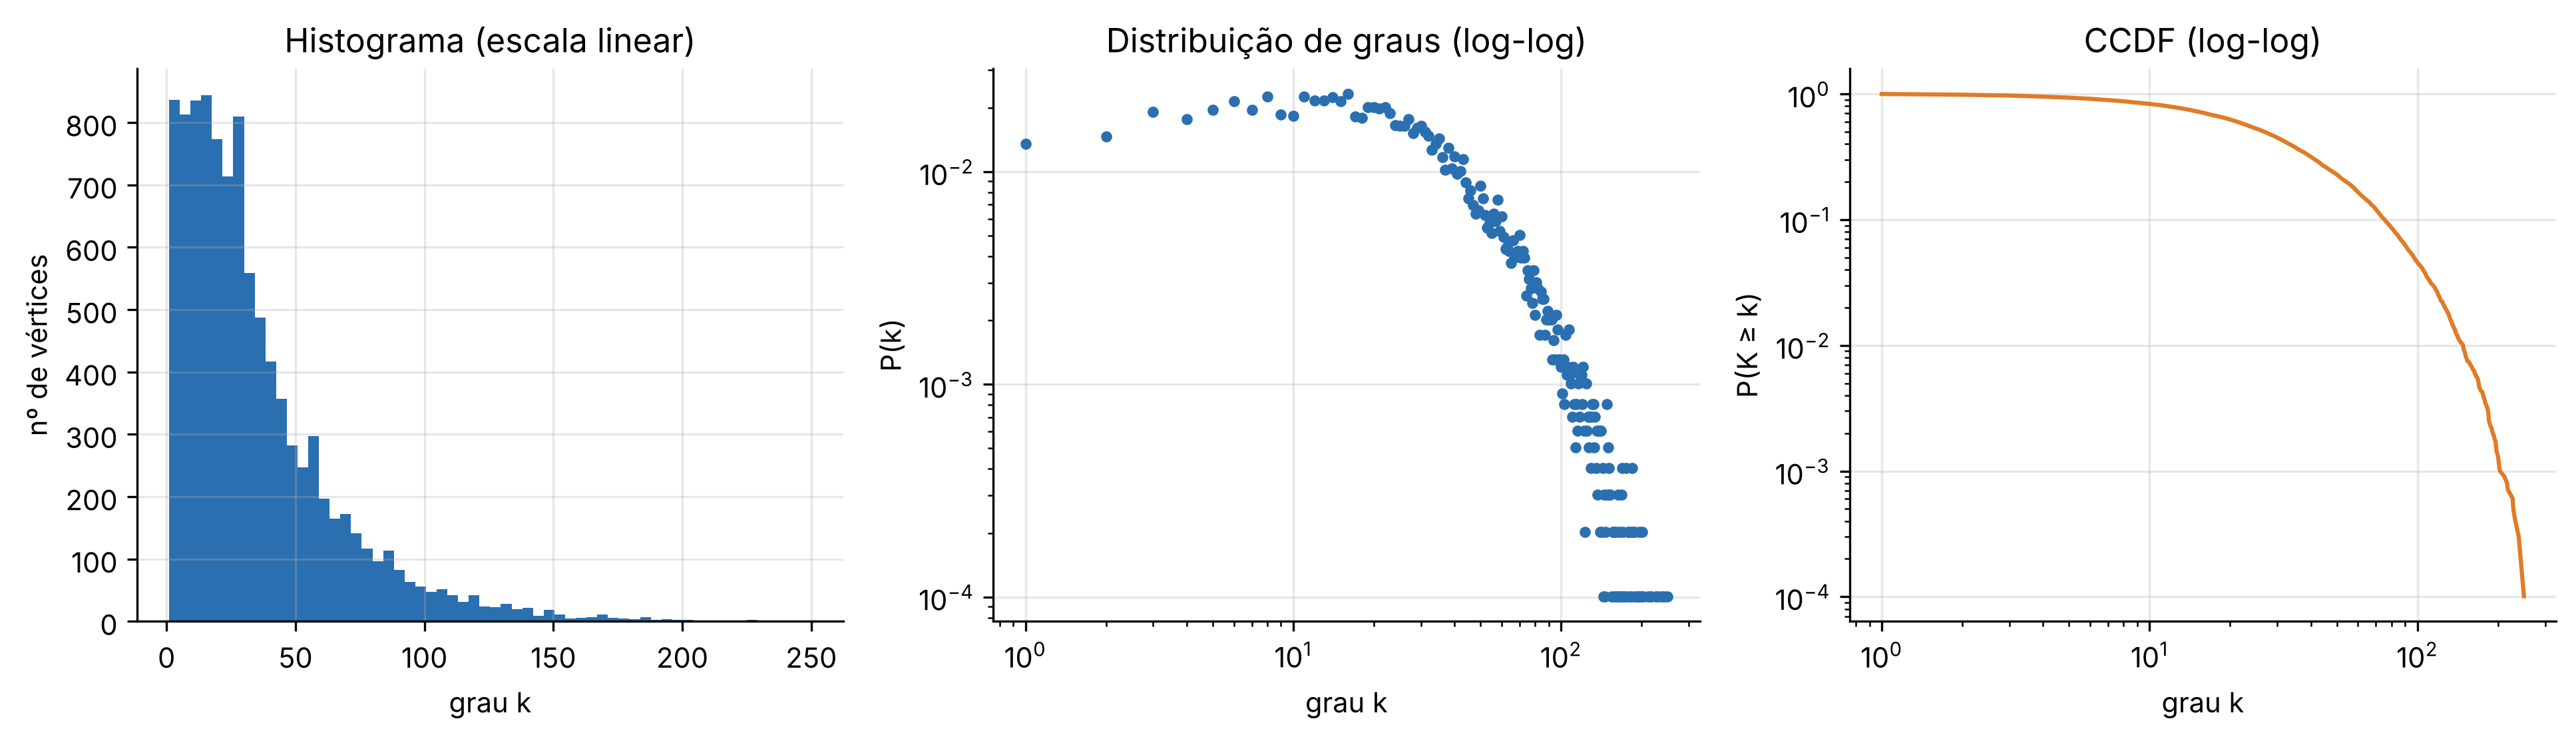

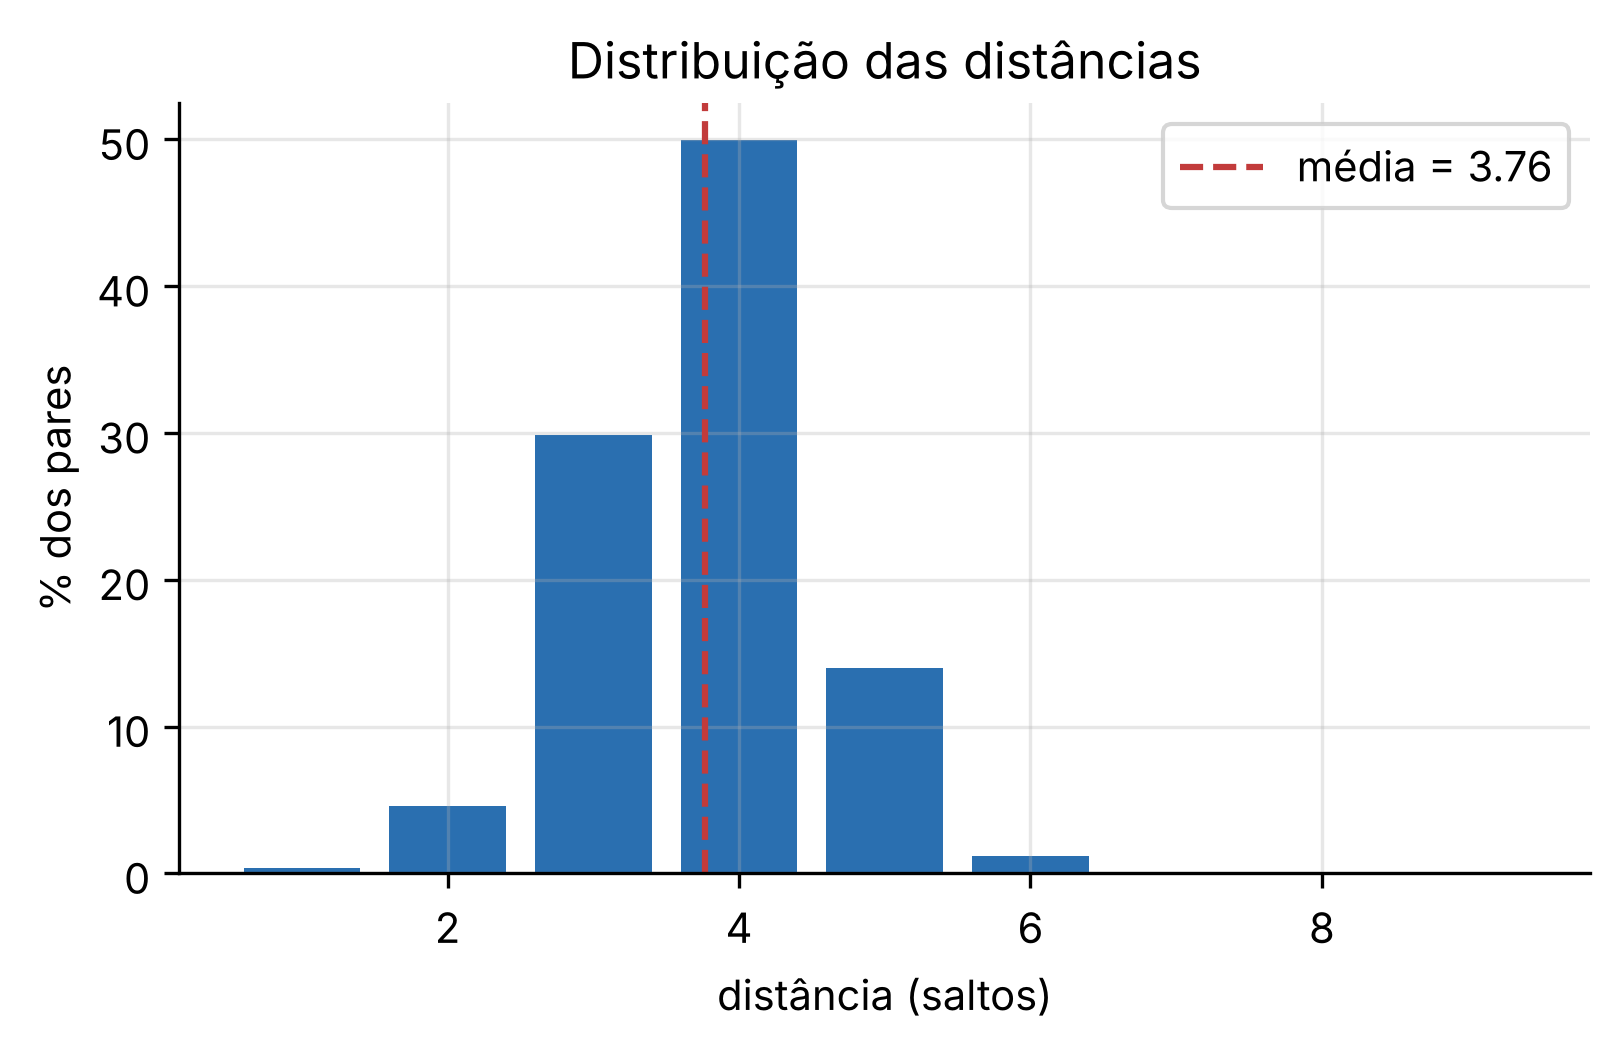

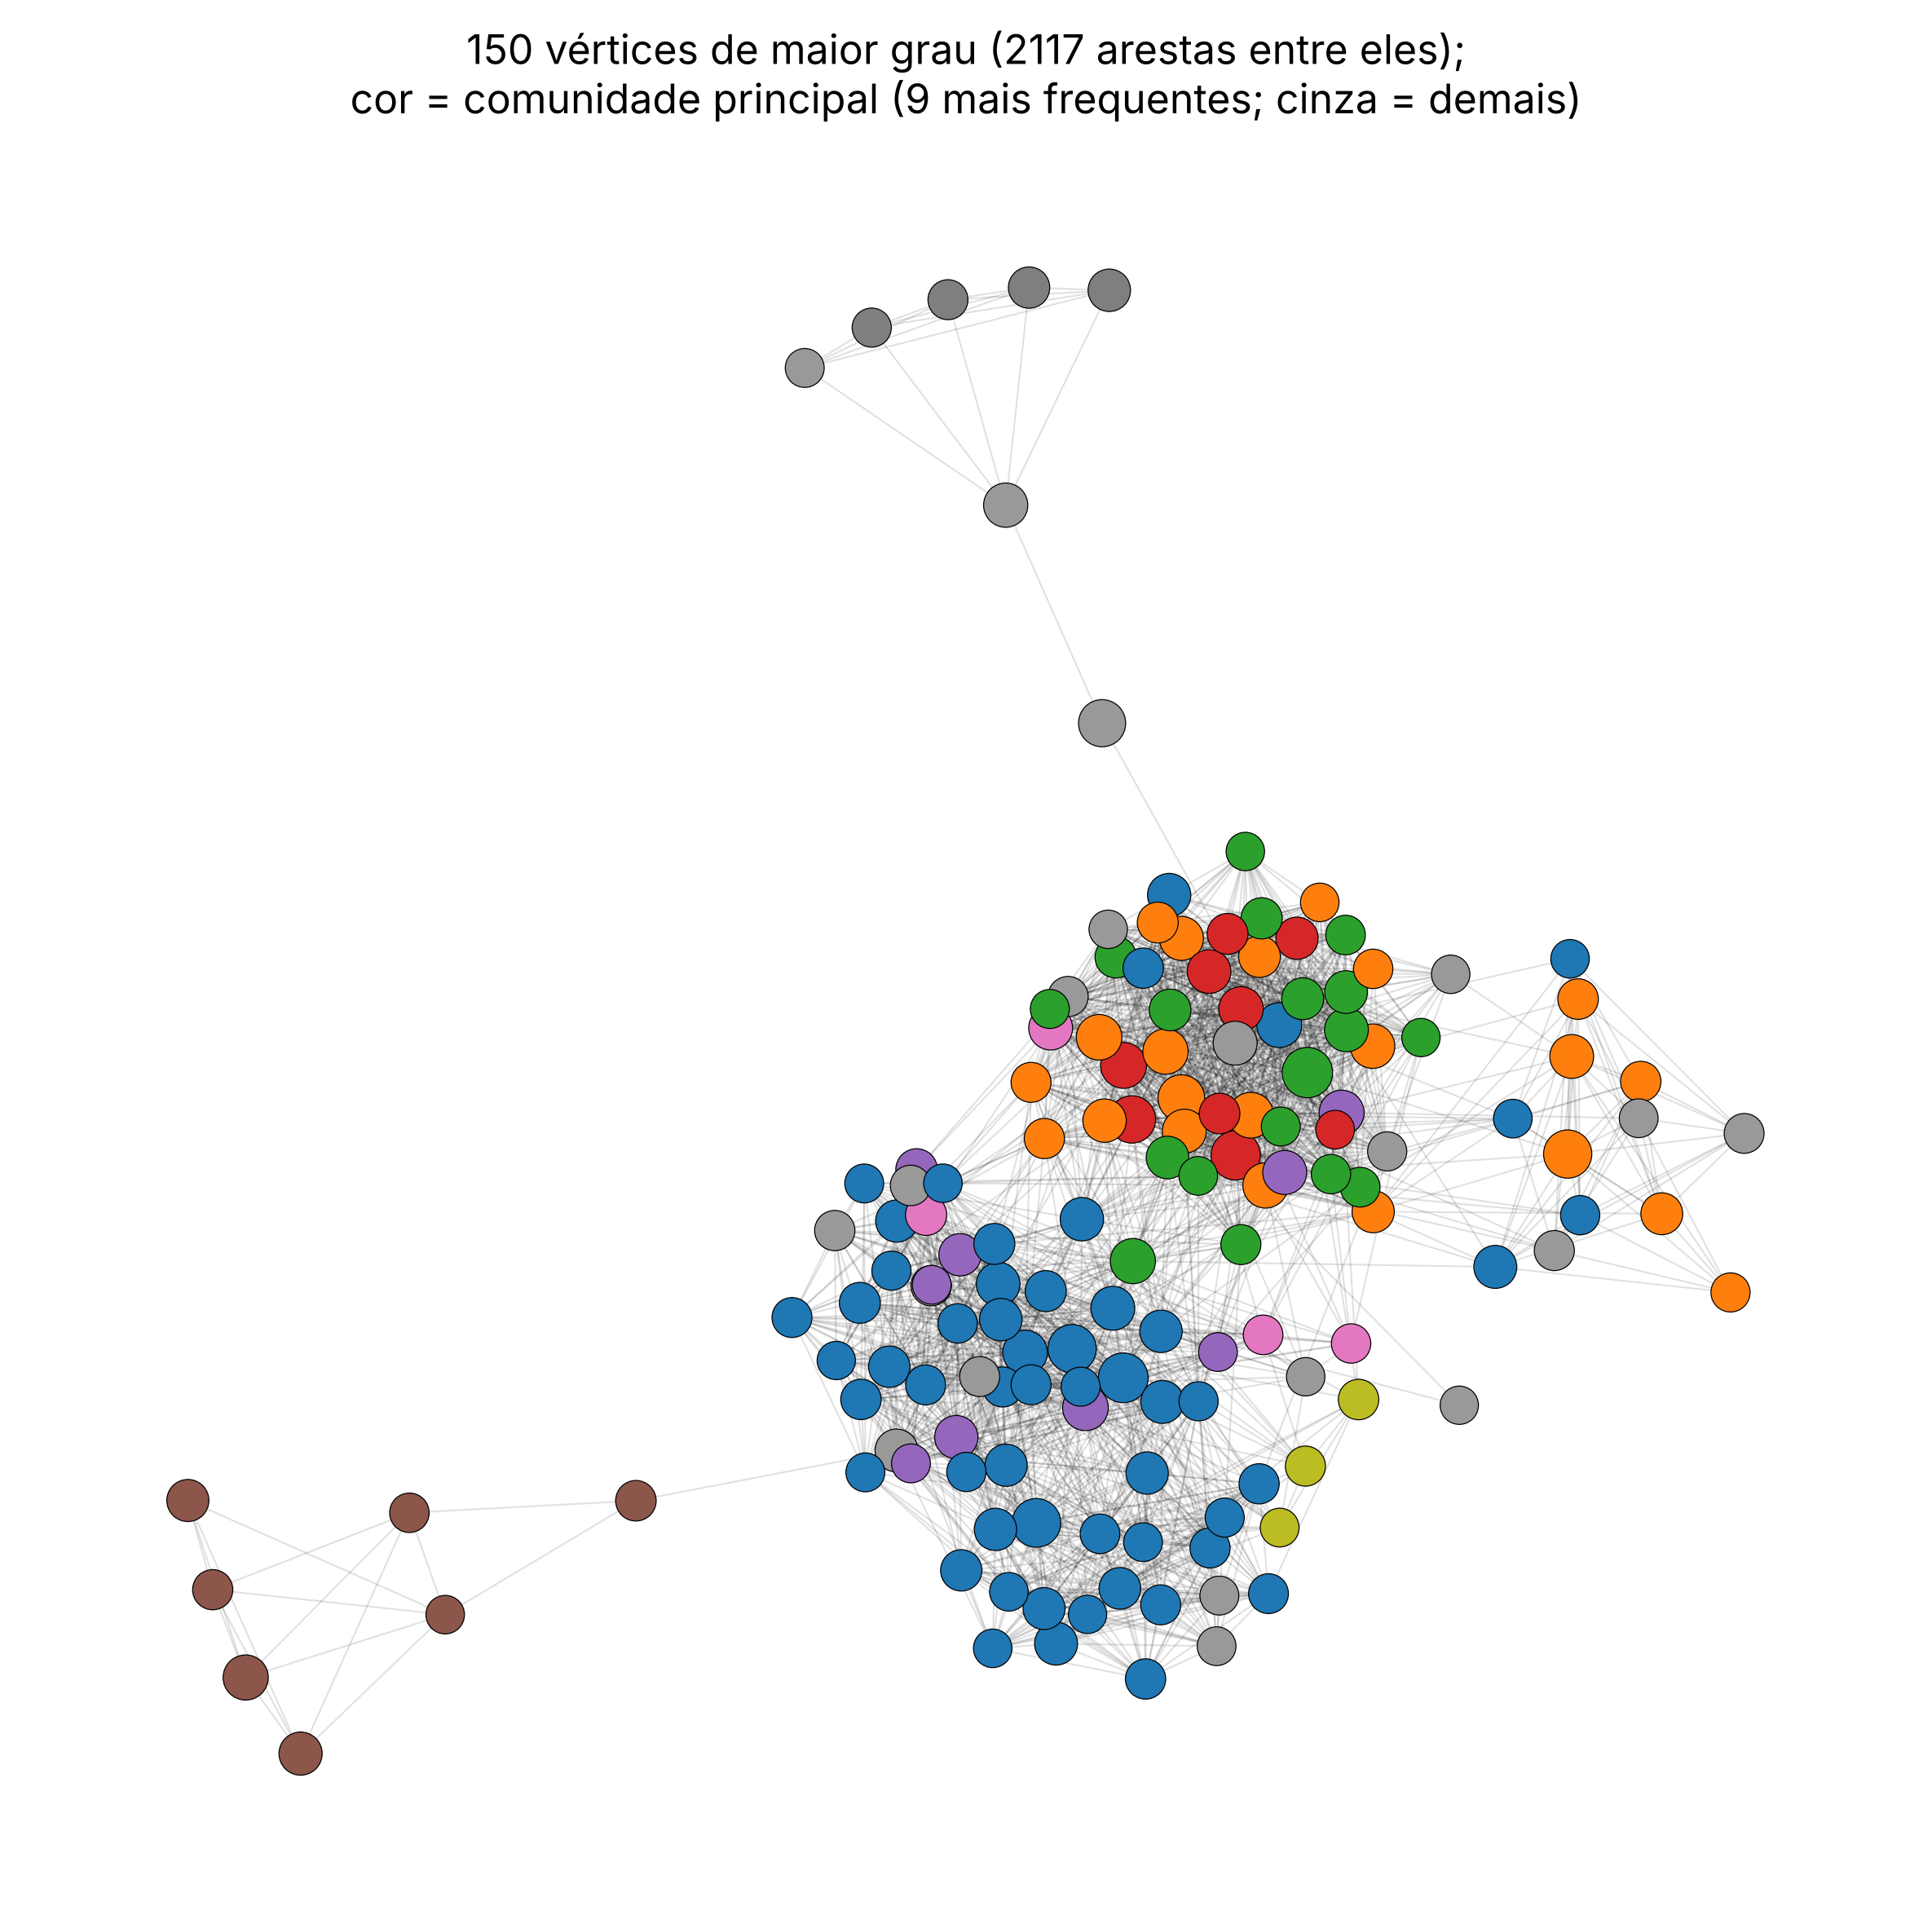

In [5]:
figura("p1_distribuicao_graus"); figura("p1_distribuicao_distancias", 500); figura("p1_visualizacao_top150", 600)

In [6]:
tabela("parte1_calculadas")

,Medida,Calculada,Método / justificativa
0,Vértices e arestas,sim,contagem direta da lista de arestas
1,Grau mín./máx./médio/mediano,sim,vetor de graus (CSR)
2,Distribuição de graus,sim,histograma log-log e CCDF (k = 0 excluído)
3,Densidade,sim,2m / (n(n-1))
4,Componentes conexas e tamanhos,sim,BFS própria
5,"Diâmetro, raio, caminho médio",sim,"exato: BFS de todos os vértices (igraph, C), em blocos; conferido com BFS própria"
6,Triângulos,sim,"implementação própria, orientação por grau O(m·√m); conferida com igraph"
7,Clusterização média e transitividade,sim,a partir dos triângulos por vértice
8,Visualização reduzida,sim,"150 vértices de maior grau, layout Kamada-Kawai"
9,Componentes fortemente conexas / Euler dirigido,não,não se aplica: com-Orkut é não direcionado


## Parte II — Algoritmos
O Orkut não tem pesos. Usamos **peso unitário** (Dijkstra = BFS, validação) e um **peso derivado dos dados**, `w(u,v) = 1/(1 + vizinhos em comum)`, que torna Dijkstra, Bellman-Ford, Floyd-Warshall e a AGM informativos (laços fortes = curtos). Tempos: 30 repetições no grafo completo (IC Normal) e 10 por tamanho em subgrafos BFS (IC t-Student).

In [7]:
r2 = analise.parte2(ctx)
import json; print(json.dumps(r2["execucao"], indent=1, ensure_ascii=False, default=str)[:3000])

{
 "fonte": 0,
 "fonte_id_original": 99,
 "bfs": {
  "alcancados": 9917,
  "excentricidade_fonte": 7,
  "vertices_por_nivel": [
   1,
   113,
   404,
   2495,
   5989,
   876,
   38,
   1
  ],
  "confere_igraph": true
 },
 "dfs": {
  "alcancados": 9917,
  "profundidade_max_arvore": 8043
 },
 "euler": {
  "conexo": true,
  "n_impares": 4930,
  "euleriano": false,
  "semi_euleriano": false
 },
 "dijkstra_unitario_igual_bfs": true,
 "dijkstra_ponderado": {
  "dist_max": 3.283643997423801,
  "dist_media": 0.3079372901878151,
  "saltos_medios_no_caminho_ponderado": 6.785923162246648,
  "saltos_max": 12
 },
 "bellman_ford": {
  "rodadas_ate_convergir": 8,
  "limite_teorico_n_menos_1": 9916,
  "ciclo_negativo": false,
  "igual_dijkstra": true
 },
 "tarjan": {
  "pontes": 138,
  "pontos_articulacao": 136,
  "confere_networkx": true,
  "pontes_com_folha": 134
 },
 "agm": {
  "peso_prim": 1183.4866797074496,
  "peso_kruskal": 1183.48667970745,
  "peso_igraph": 1183.4866797074337,
  "arestas": 99

,Algoritmo,Complexidade,Repetições,Média (ms),DP (ms),IC95 inf. (ms),IC95 sup. (ms),Método do IC
0,BFS,O(n+m),30,13.140392,0.390868,13.000524,13.280259,Normal (z)
1,DFS,O(n+m),30,15.236257,3.996699,13.806083,16.666431,Normal (z)
2,Euler (verificação),O(n+m),30,14.430453,0.492289,14.254293,14.606613,Normal (z)
3,Dijkstra,O((n+m) log n),30,62.805664,9.205261,59.511664,66.099664,Normal (z)
4,Bellman-Ford,O(n·m) [efetivo O(k·m)],30,153.391533,10.309379,149.702436,157.080629,Normal (z)
5,Tarjan (pontes/articulações),O(n+m),30,31.838527,2.245282,31.035078,32.641976,Normal (z)
6,Prim,O(m log n),30,263.182745,16.791285,257.174172,269.191319,Normal (z)
7,Kruskal,O(m log m),30,109.479326,6.055474,107.312442,111.646210,Normal (z)


,Algoritmo,"f(n,m)",c,R² (c·f),a (ms/vértice),b (ms/aresta),R² (a·n+b·m)
0,BFS,O(n+m),0.000088,0.990978,-0.000876,0.000144,0.995186
1,DFS,O(n+m),0.000090,0.976436,-0.001197,0.000166,0.983208
2,Euler (verificação),O(n+m),0.000101,0.976718,-0.001327,0.000184,0.983374
3,Dijkstra,O((n+m) log n),0.000022,0.997773,-0.002712,0.000455,0.996014
4,Bellman-Ford,O(n·m) [efetivo O(k·m)],0.000054,0.996820,-0.000703,0.000919,0.996993
5,Tarjan (pontes/articulações),O(n+m),0.000194,0.994818,-0.001335,0.000284,0.997027
6,Prim,O(m log n),0.000102,0.980959,-0.033018,0.003261,0.989789
7,Kruskal,O(m log m),0.000035,0.996344,-0.004277,0.000855,0.994880


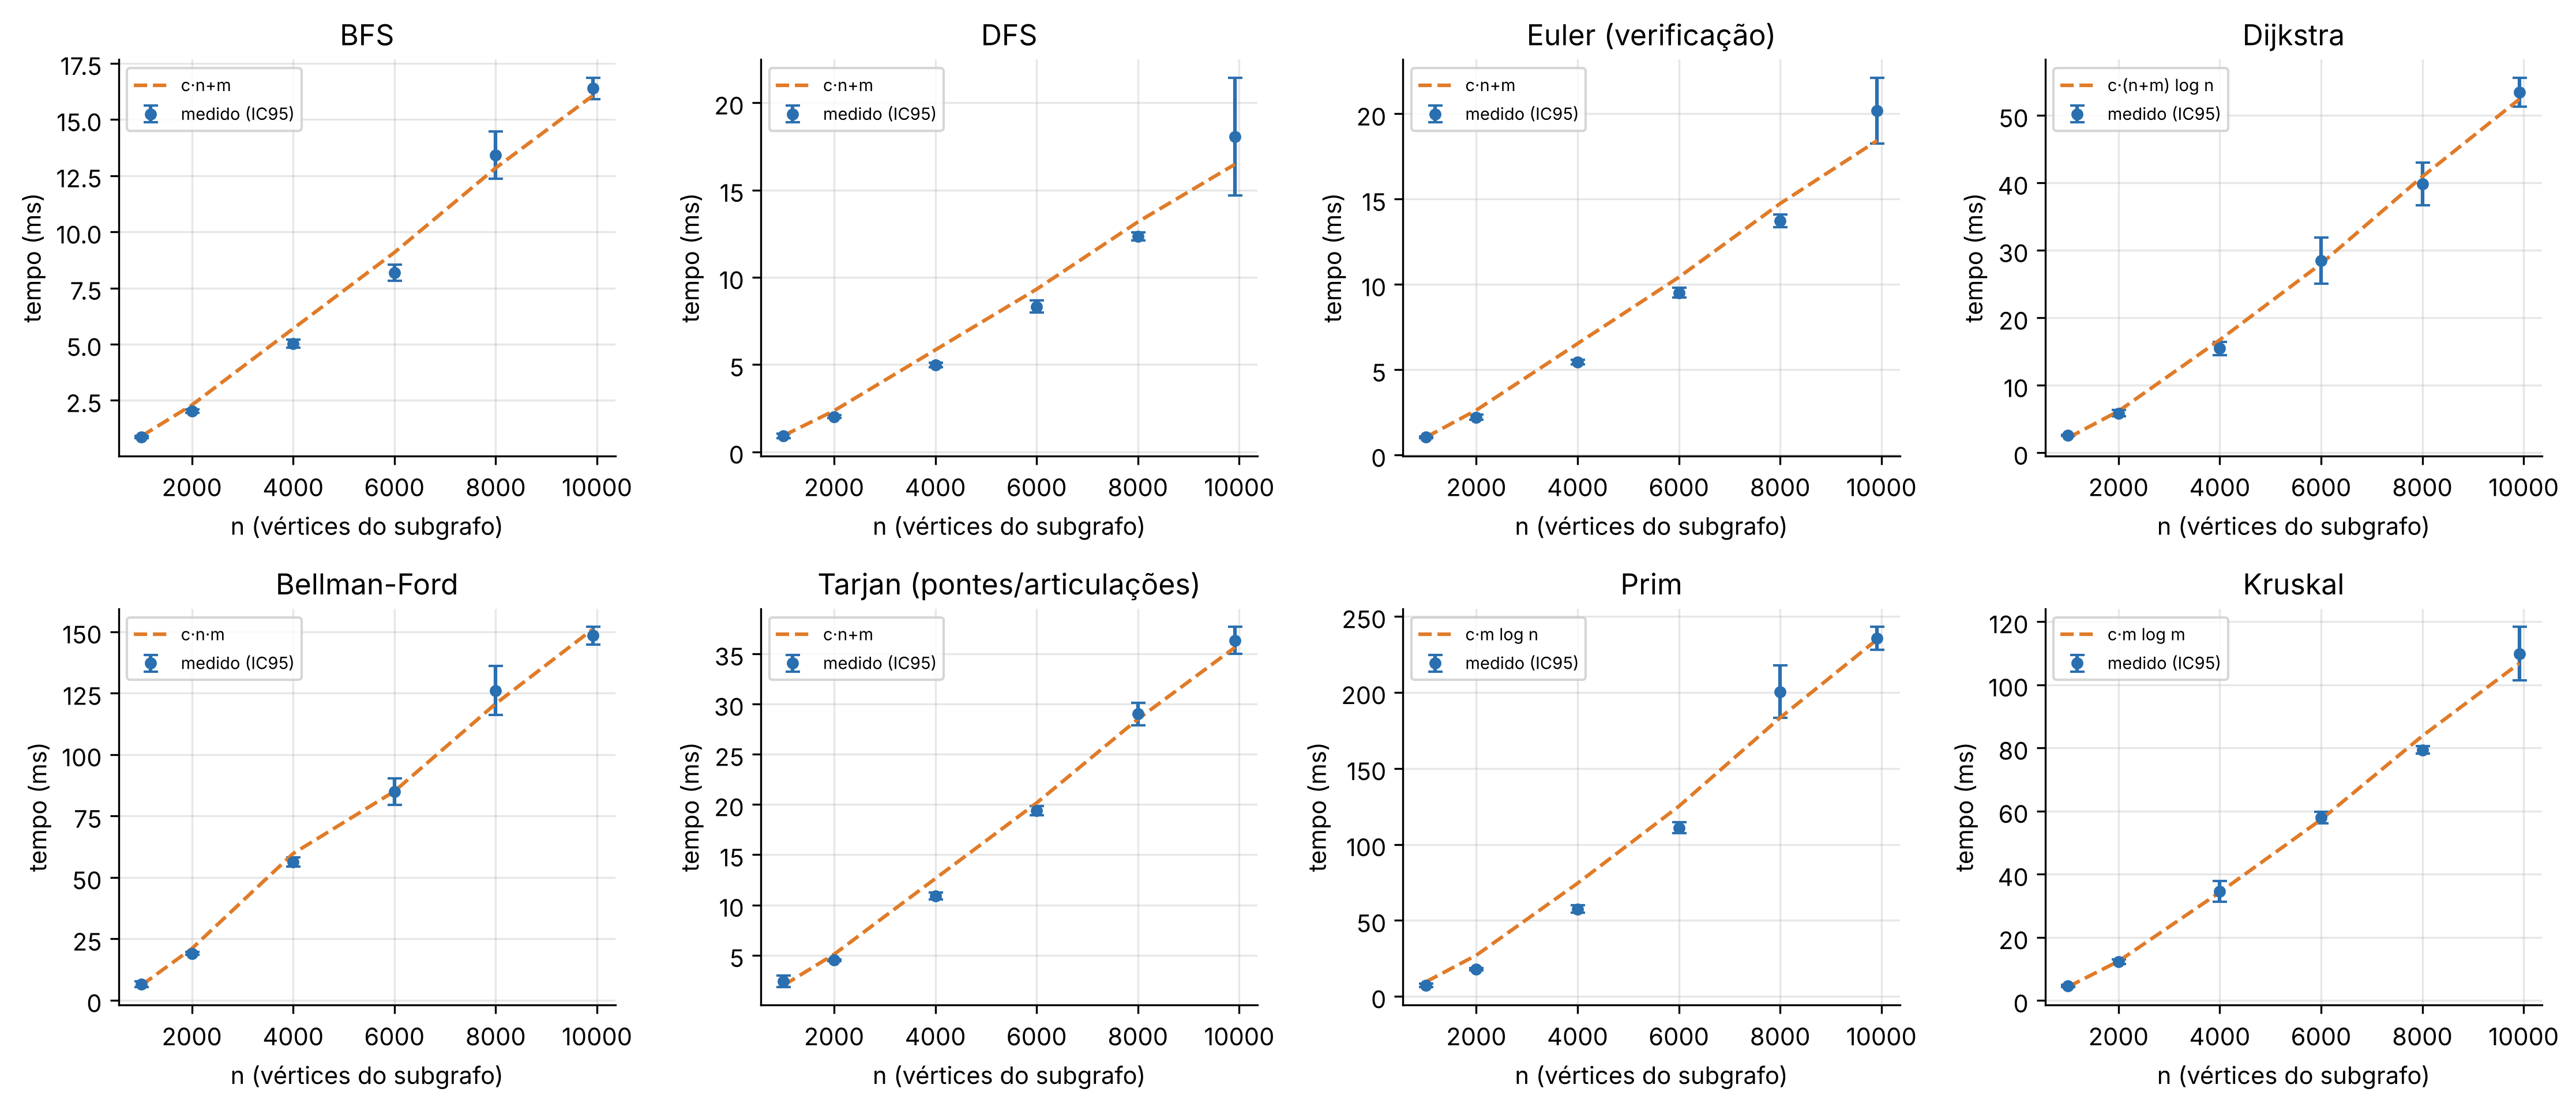

In [8]:
tabela("parte2_tempos_grafo_completo"); tabela("parte2_ajustes"); figura("p2_escala_tempos")

,Versão,n,m,Repetições,Média (ms),DP (ms),IC95 inf. (ms),IC95 sup. (ms),Método do IC
0,Floyd-Warshall (numpy),200,965,10,10.300414,0.513113,9.933355,10.667473,t-Student (9 g.l.)
1,Floyd-Warshall (numpy),400,3503,10,101.582943,8.234263,95.692506,107.473380,t-Student (9 g.l.)
2,Floyd-Warshall (numpy),600,4936,10,389.249659,9.822423,382.223120,396.276197,t-Student (9 g.l.)
3,Floyd-Warshall (numpy),800,6637,10,909.524937,43.911949,878.112221,940.937653,t-Student (9 g.l.)
4,Floyd-Warshall (numpy),1000,9305,10,1565.398035,46.897017,1531.849930,1598.946139,t-Student (9 g.l.)
5,Floyd-Warshall (numpy),1200,11807,10,3156.581844,177.266697,3029.772889,3283.390800,t-Student (9 g.l.)
6,Floyd-Warshall (Python),50,201,10,3.823121,0.155670,3.711761,3.934481,t-Student (9 g.l.)
7,Floyd-Warshall (Python),100,426,10,25.554806,1.088185,24.776365,26.333247,t-Student (9 g.l.)
8,Floyd-Warshall (Python),150,685,10,90.079648,6.115780,85.704682,94.454614,t-Student (9 g.l.)
9,Floyd-Warshall (Python),200,965,10,206.860900,3.770364,204.163745,209.558056,t-Student (9 g.l.)


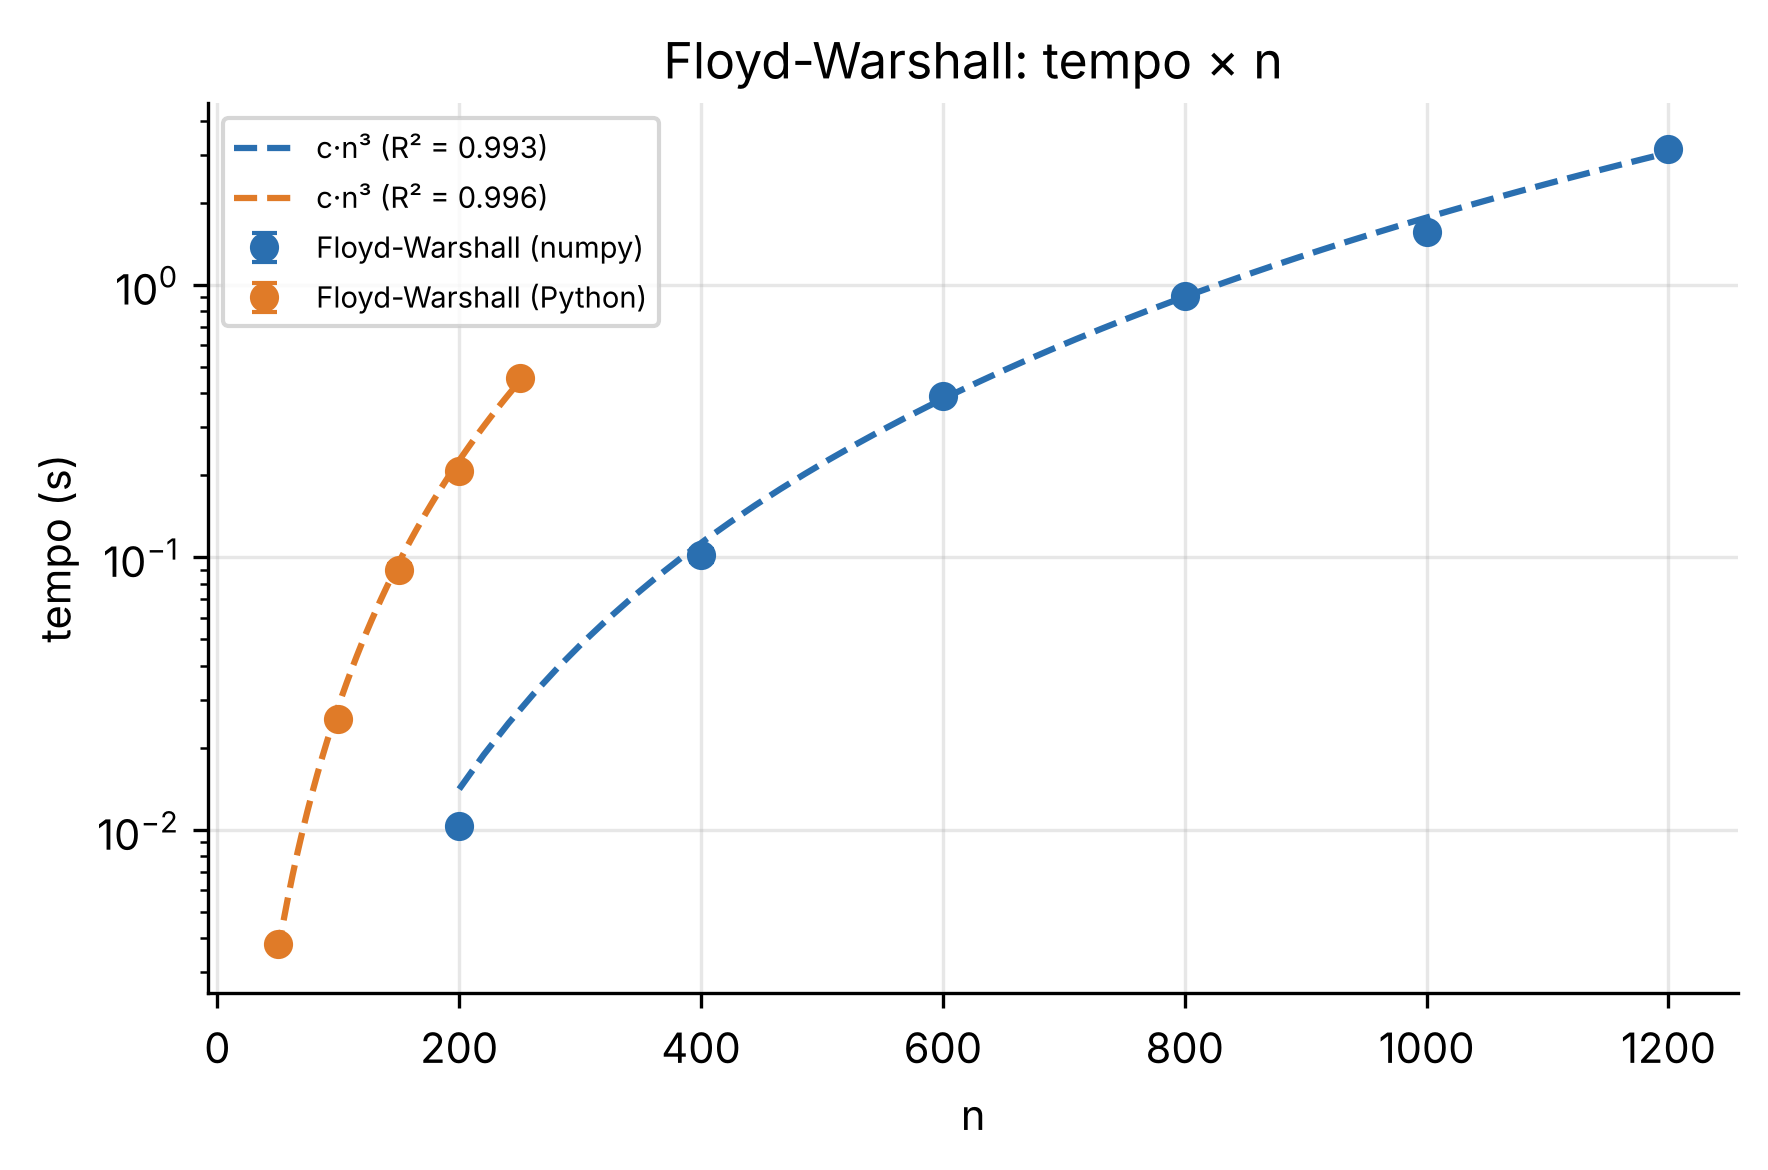

{'validacao': {'n': 150, 'numpy_igual_python': True, 'igual_dijkstra_todas_fontes': True}, 'ajustes': {'Floyd-Warshall (numpy)': {'c_s_por_n3': 1.7623653314121752e-09, 'r2': 0.9927922962400979, 'estimativa_grafo_completo_s': 1718.8456550054693}, 'Floyd-Warshall (Python)': {'c_s_por_n3': 2.8285710857109155e-08, 'r2': 0.9960053458100849, 'estimativa_grafo_completo_s': 27587.22629122822}}, 'memoria_matriz_grafo_completo_MB': 786.775112, 'operacoes_grafo_completo': 975306098213}


In [9]:
tabela("parte2_floyd_warshall"); figura("p2_floyd_warshall", 550)
print({k: v for k, v in r2["floyd_warshall"].items() if k != "medicoes"})

## Parte III — Redes complexas
### 1. Small-world (cálculo próprio de σ e ω contra G(n,m) e contra o modelo de configuração)

,Referência,C,C_ref,C/C_ref,L,L_ref,L/L_ref,σ,ω,Small-world?
0,"Erdős–Rényi G(n,m)",0.370304,0.003524,105.095069,3.764057,2.896354,1.299585,80.868203,0.260763,True
1,"Configuração (trocas duplas, graus preservados)",0.370304,0.010767,34.391957,3.764057,2.933947,1.282933,26.807295,0.270751,True


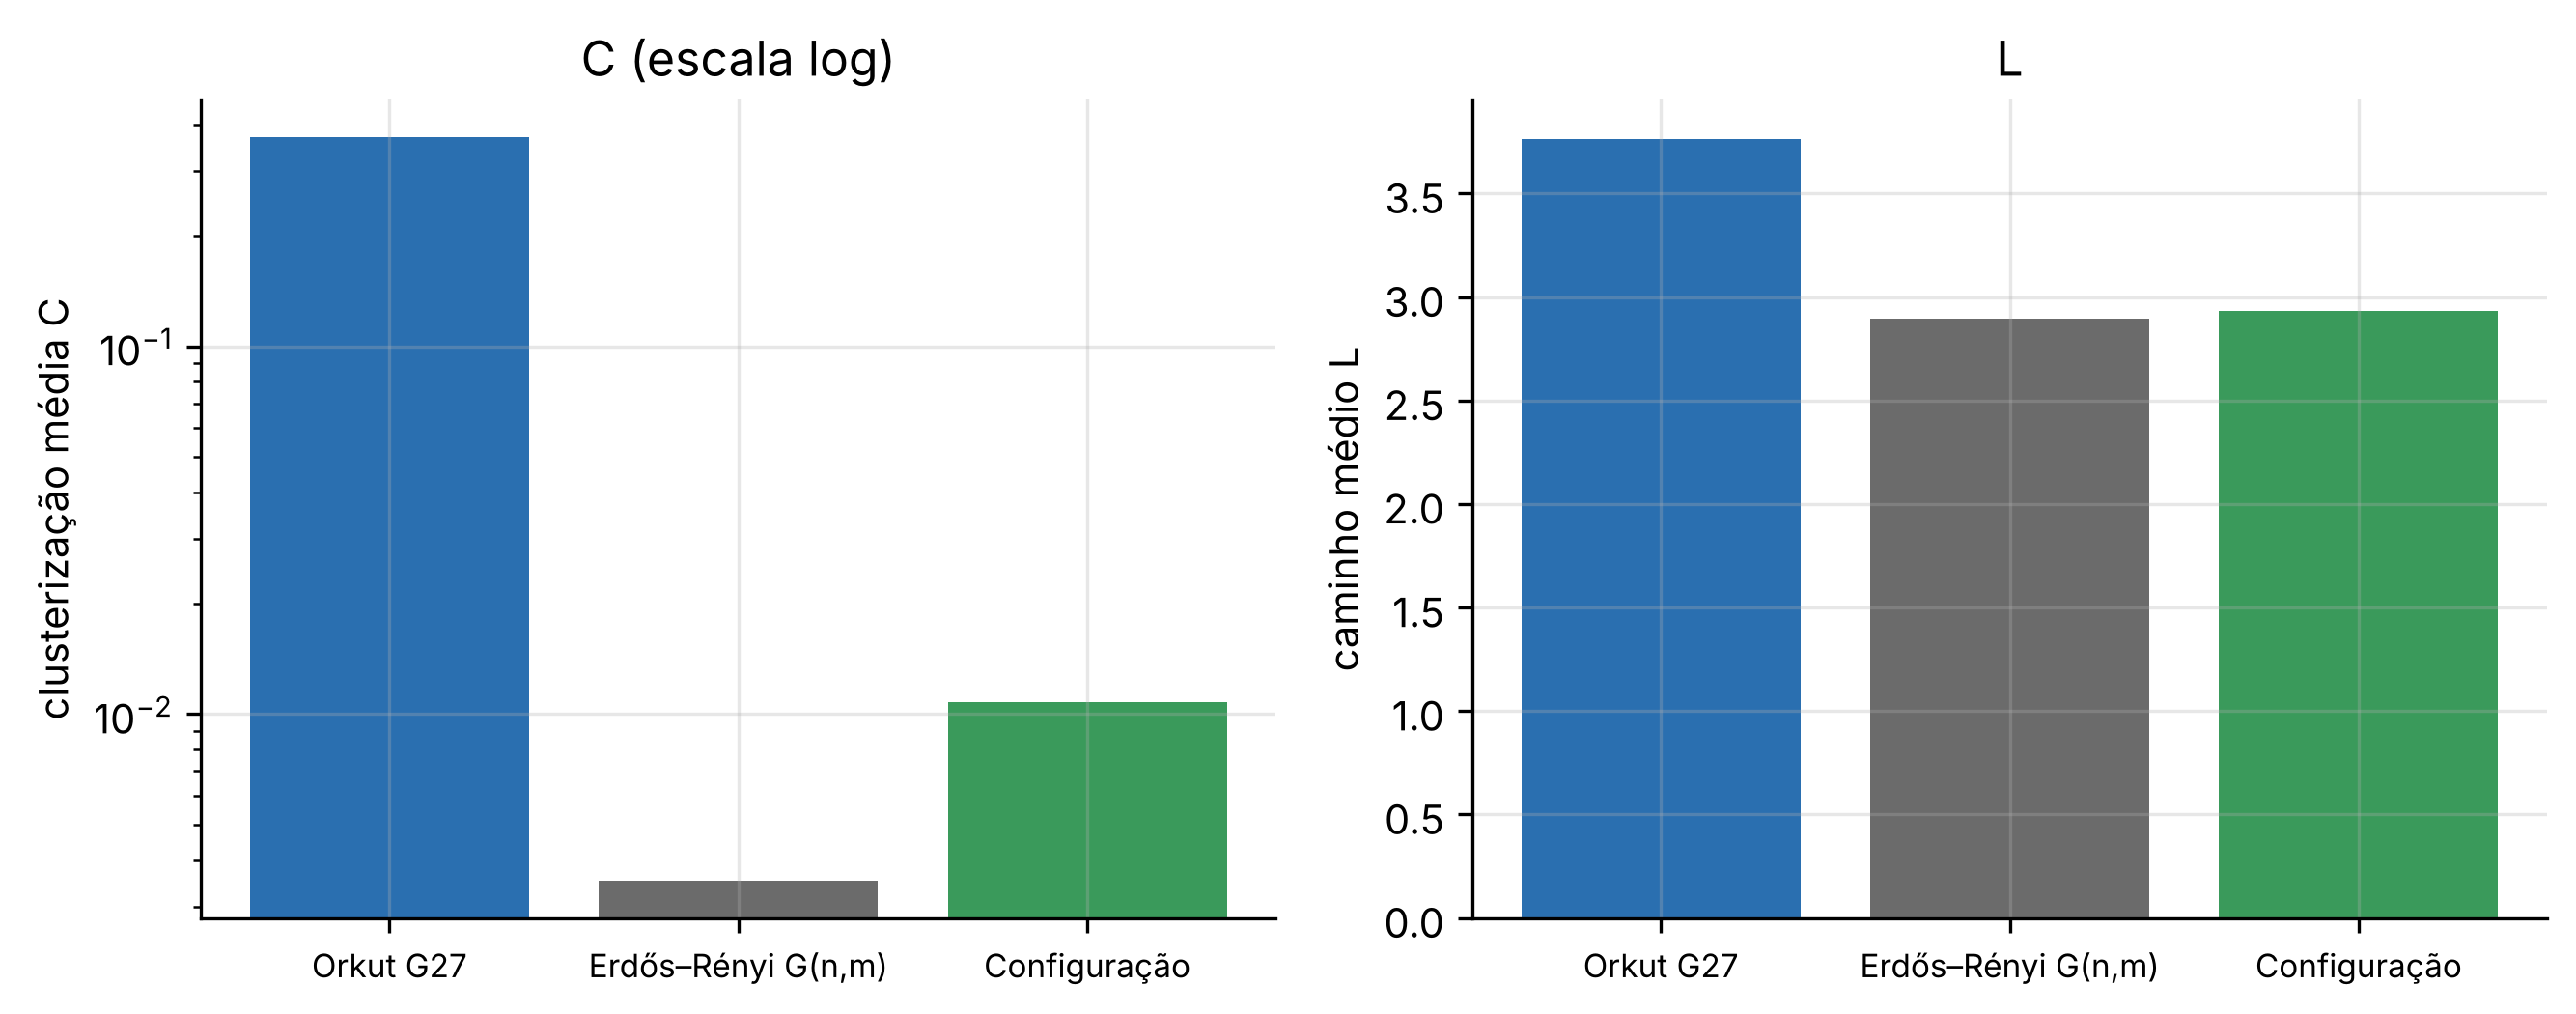

In [10]:
r3 = analise.small_world(ctx); tabela("parte3_small_world"); figura("p3_small_world", 700)

### 2. Lei de potência (regressões, CCDF e MLE com k_min por KS) — subgrafo e Orkut completo

,Grafo,γ regressão bruta,R² bruta,γ bins log,R² bins,γ CCDF,γ MLE,k_min,cauda,KS,vs exp.,p (Vuong),vs Poisson
0,"Subgrafo G27 (LCC, 9.917 vértices)",1.611585,0.738816,0.939750,0.570962,2.851712,5.997377,119.0,259,0.057115,exponencial,3.583055e-03,lei de potência
1,Orkut completo (3.072.441 vértices),2.127258,0.843153,1.920169,0.890287,2.925446,2.962507,168.0,289226,0.015965,lei de potência,6.082727e-252,lei de potência


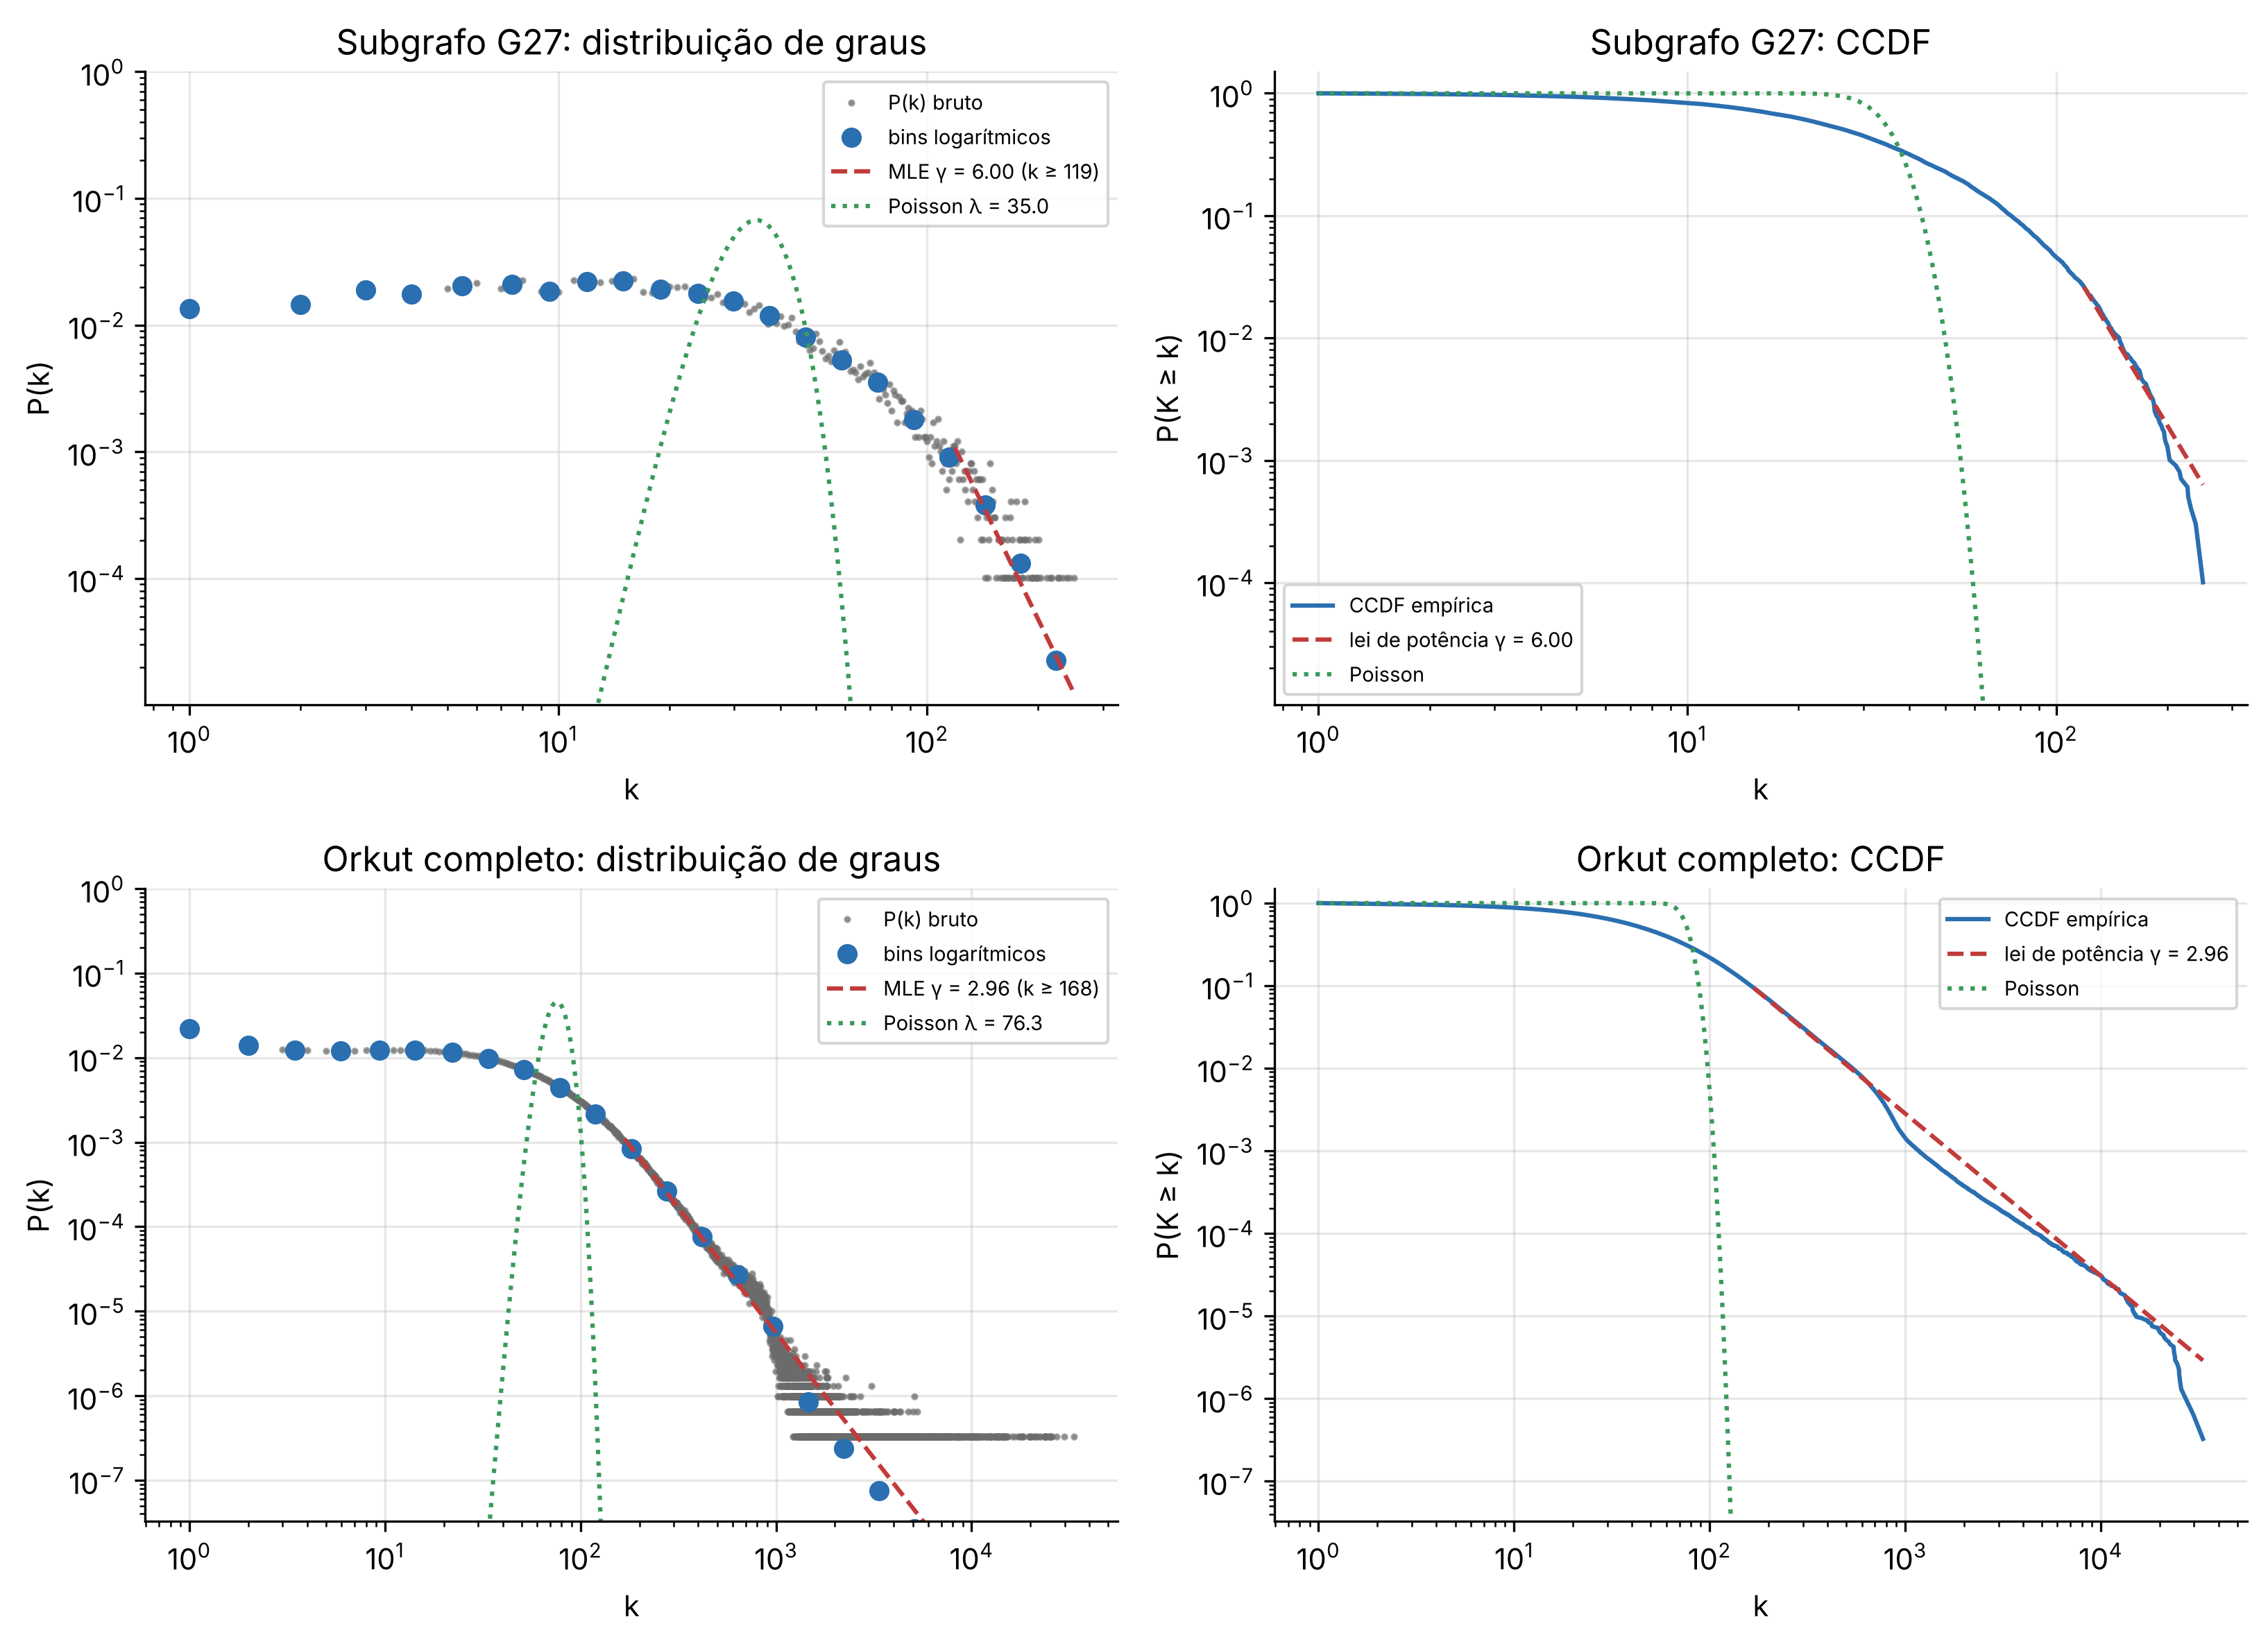

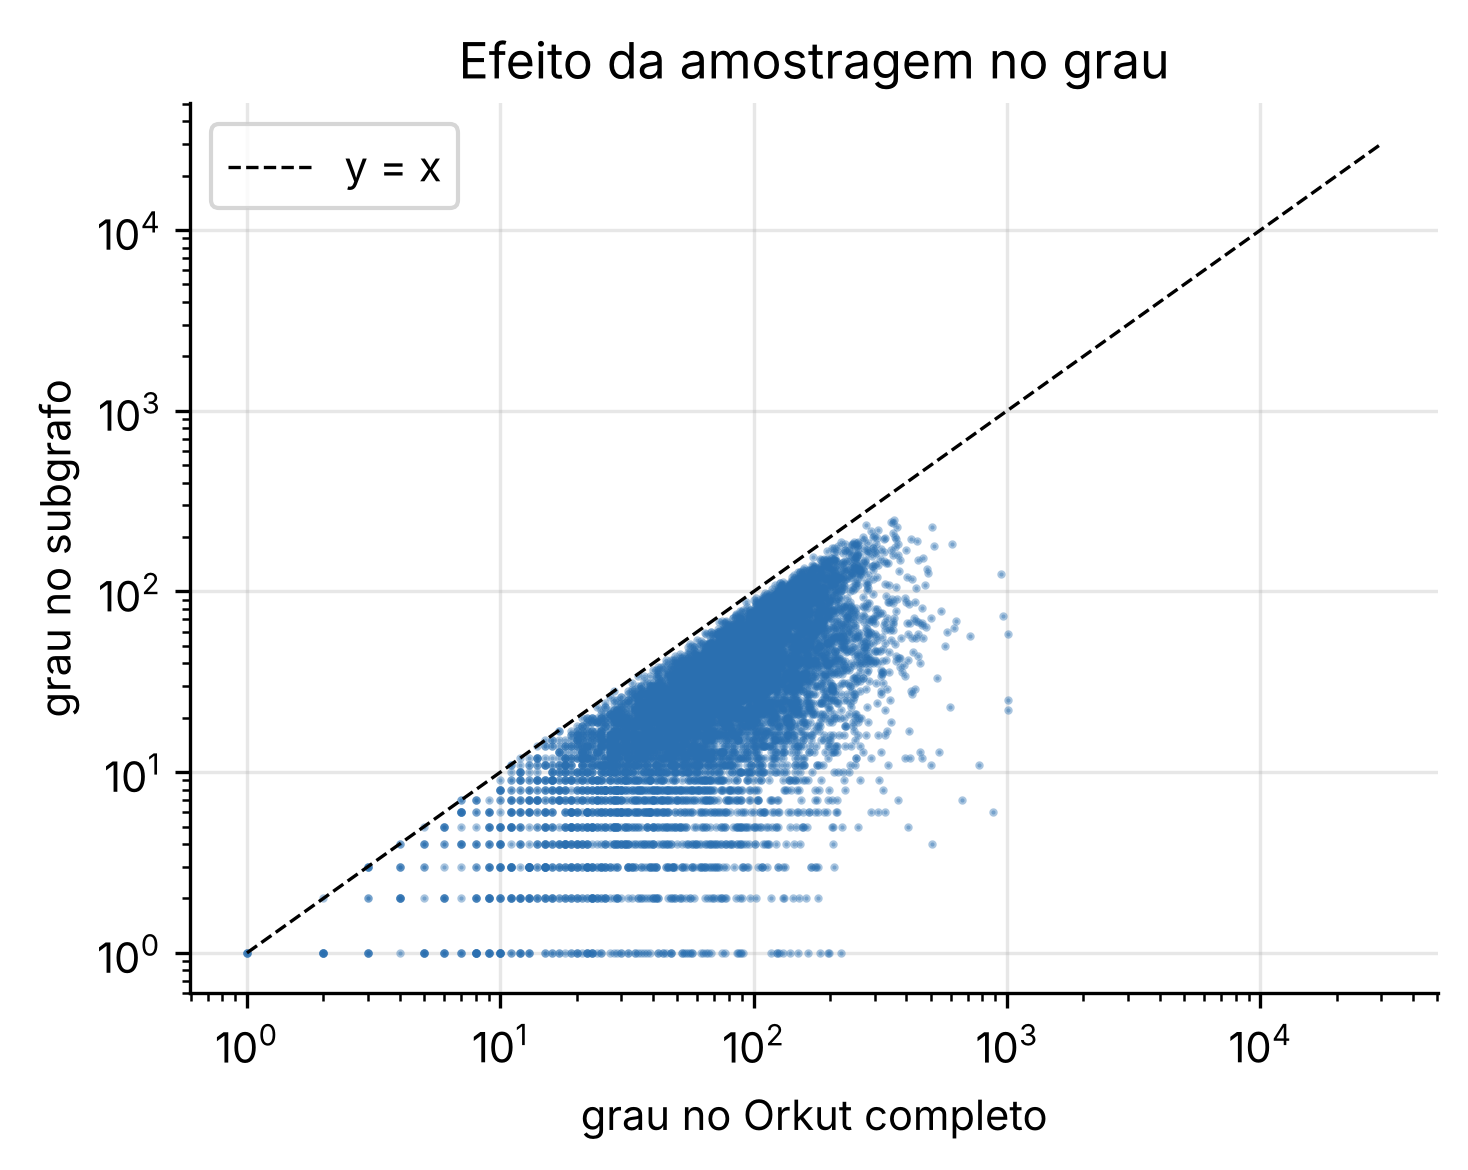

In [11]:
r4 = analise.lei_potencia(ctx); tabela("parte3_lei_potencia"); figura("p3_lei_potencia"); figura("p3_grau_original_vs_subgrafo", 450)

### 3. Robustez: 5% aleatório × 5% mais centrais (grau, betweenness, PageRank)

,Estratégia,S (fração na LCC),c (componentes),L (caminho médio),E (eficiência)
0,Sem remoção,1.000000,1.000000,3.777776,0.279881
1,Aleatória (média de 30),0.999215,7.833333,3.795981,0.278391
2,Ataque: Grau,0.999045,8.000000,4.024572,0.261992
3,Ataque: Betweenness,0.995966,36.000000,4.245752,0.247055
4,Ataque: PageRank,0.997559,22.000000,4.146610,0.255223


,Métrica,Média,DP,IC95 inf.,IC95 sup.,Método
0,S,0.999215,0.000369,0.999082,0.999347,Normal (z)
1,c,7.833333,2.865771,6.807849,8.858817,Normal (z)
2,L,3.795981,0.028455,3.785798,3.806163,Normal (z)
3,E,0.278391,0.002162,0.277617,0.279164,Normal (z)


{'pagerank_iteracoes': 97, 'pagerank_confere_igraph_maxdif': 6.384765762965094e-13, 'brandes_fontes': 1000, 'brandes_segundos': 32.976891136000006, 'spearman_brandes_amostrado_vs_exato': 0.9757927369337004, 'sobreposicao_top100_amostrado_vs_exato': 0.87}


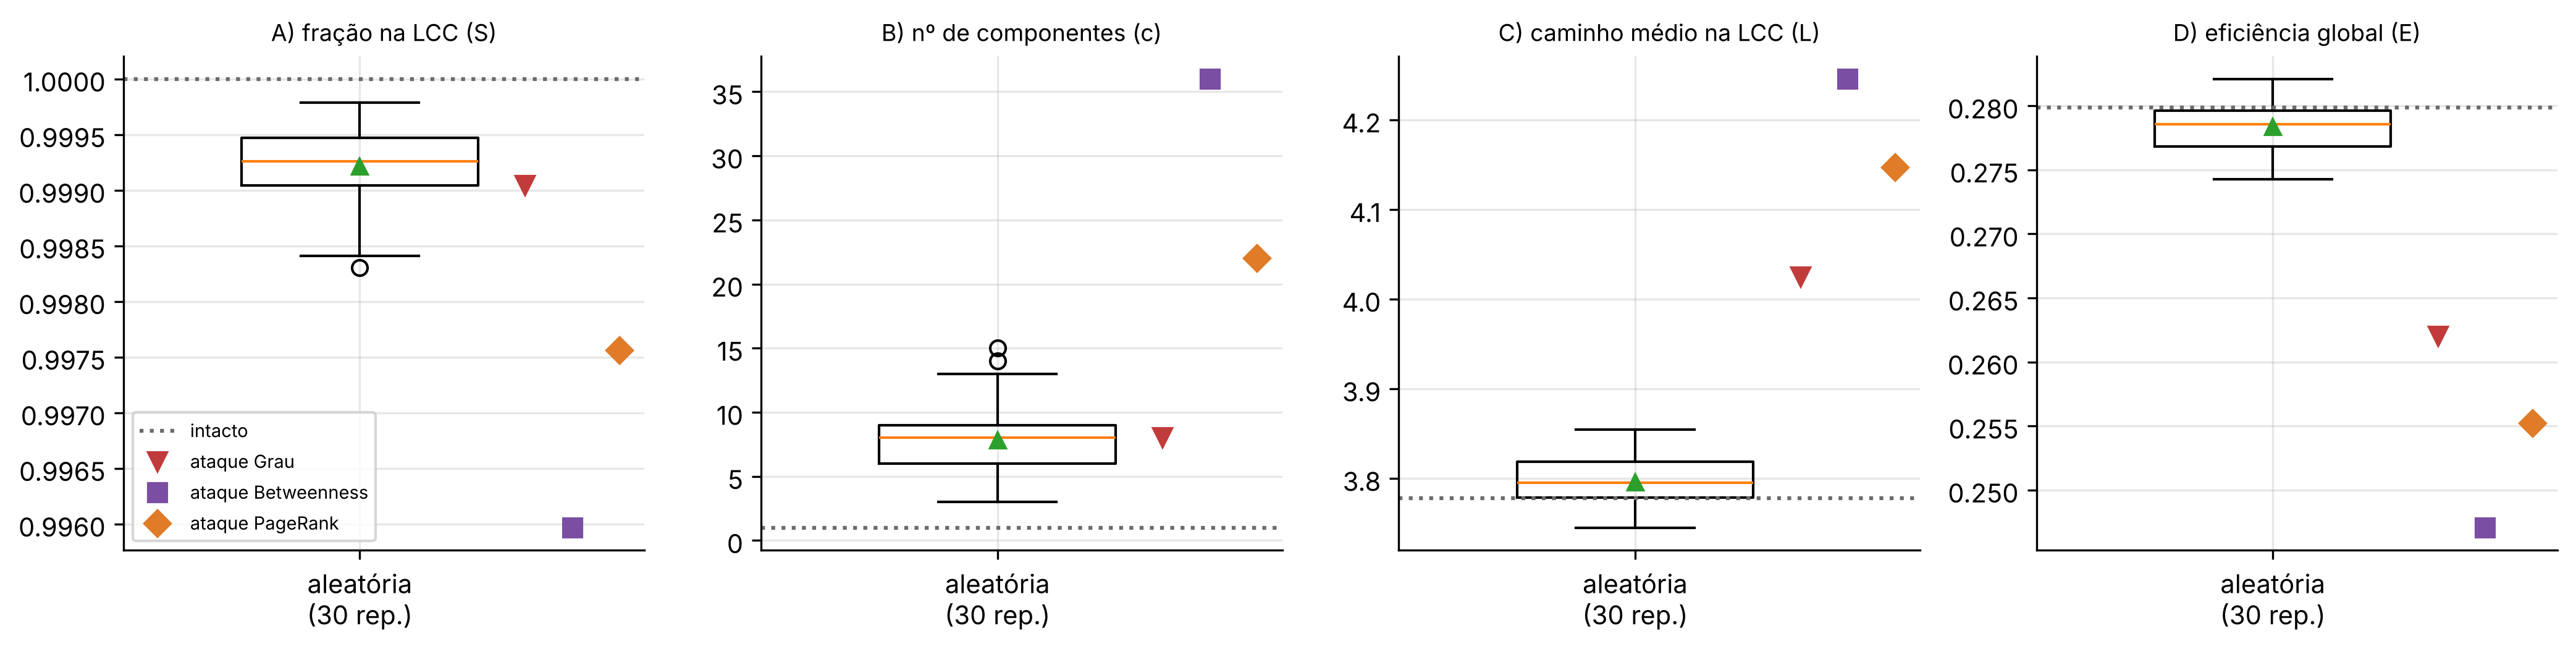

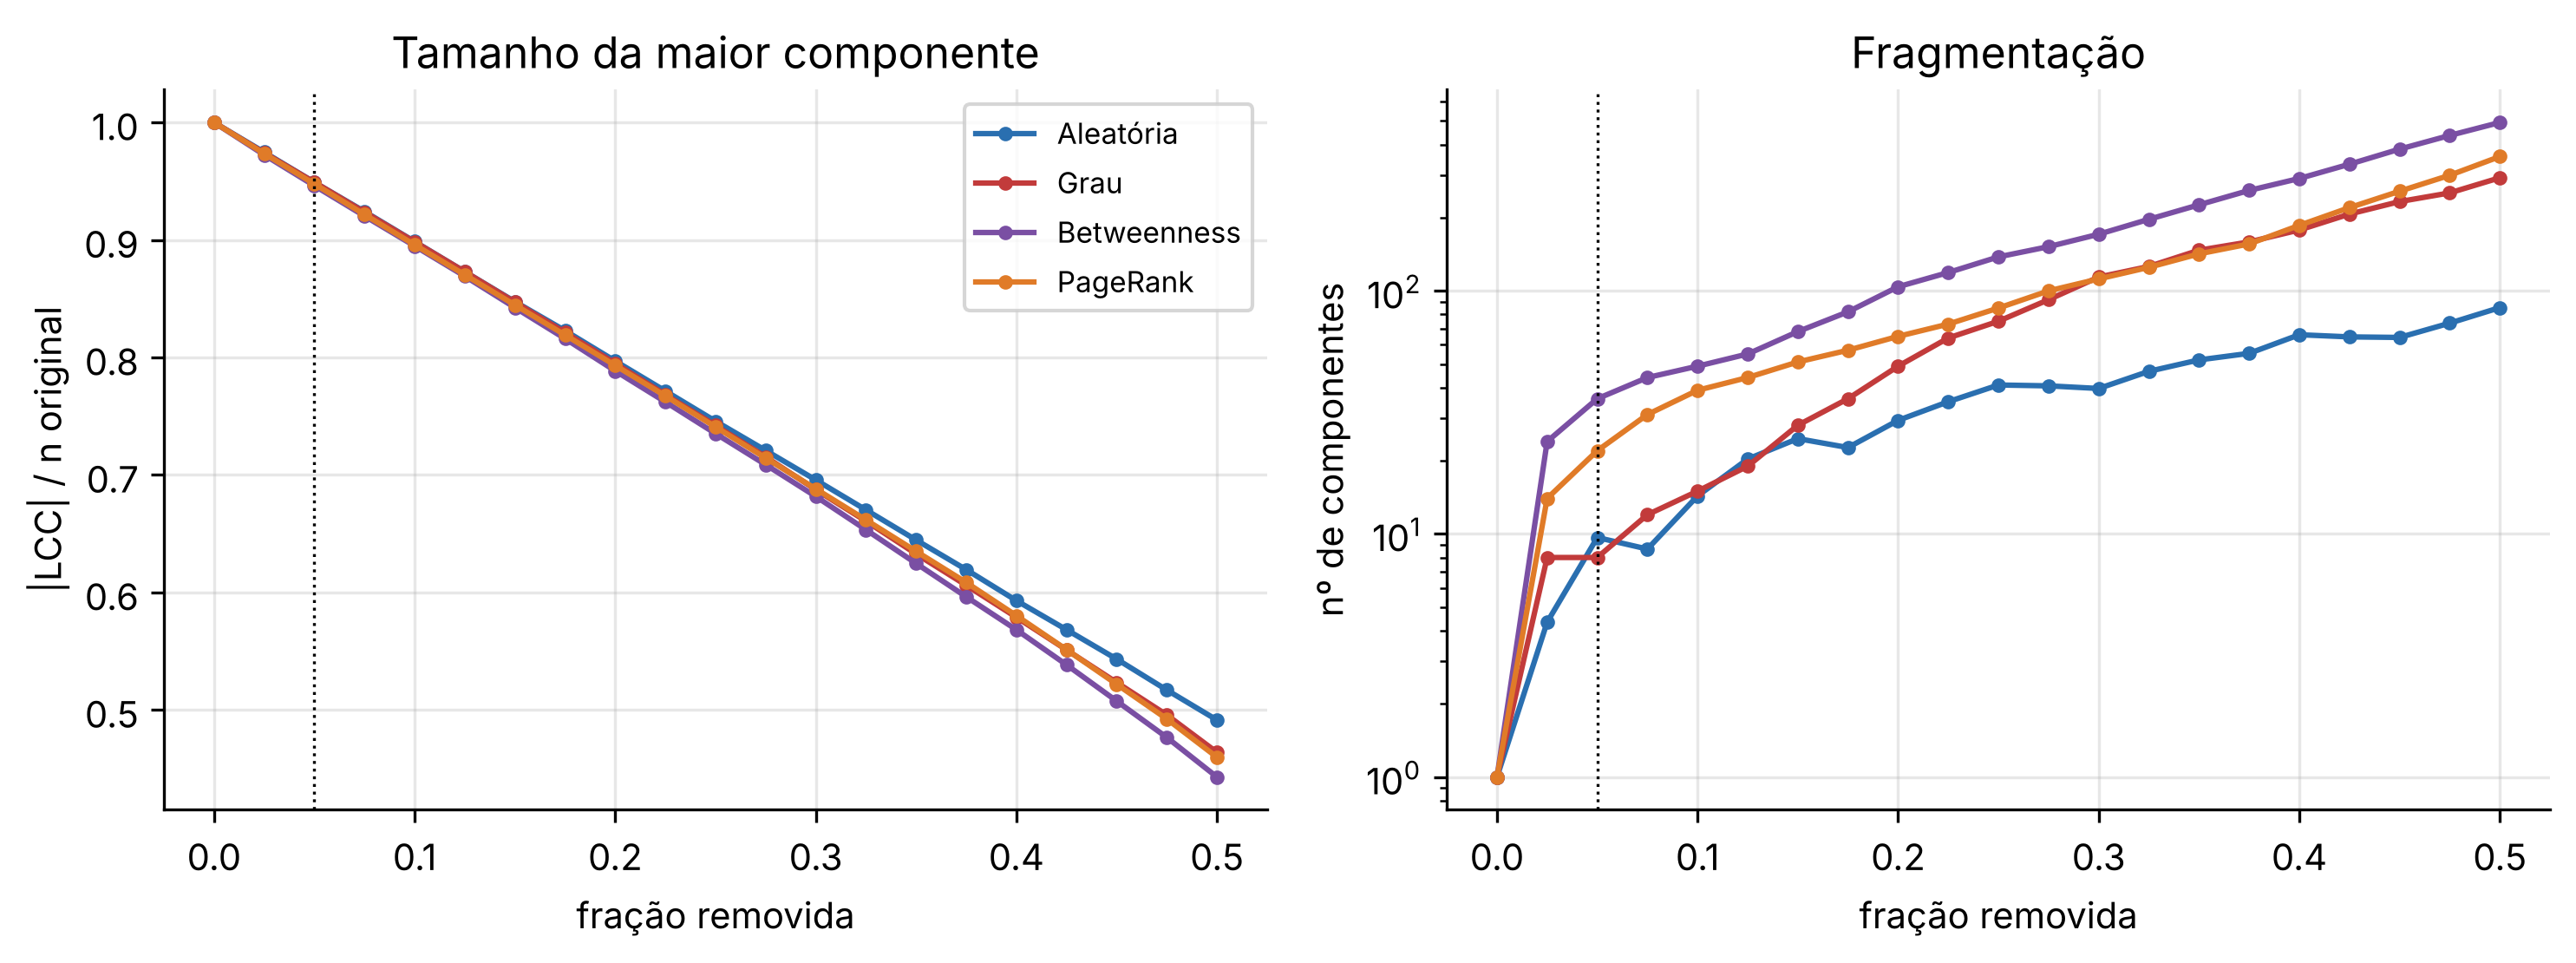

In [12]:
r5 = analise.robustez(ctx); tabela("parte3_robustez"); tabela("parte3_robustez_aleatoria_ic")
print(r5["centralidades"]); figura("p3_robustez_5pct"); figura("p3_robustez_curvas")

### 4. Descoberta

,id Orkut,grau (subgrafo),grau (Orkut completo),betweenness,PageRank,clusterização local,nº comunidades
0,378358,250,358,0.002477,0.000363,0.214458,2
1,94761,243,349,0.002292,0.000382,0.163997,2
2,171264,239,355,0.001609,0.000342,0.234099,3
3,98891,232,278,0.001240,0.000351,0.242312,2
4,96420,228,507,0.004168,0.000379,0.174279,1
5,12173,227,369,0.001662,0.000328,0.255702,3
6,499180,218,309,0.000950,0.000305,0.266647,3
7,177048,216,291,0.017836,0.000757,0.056460,1
8,246019,211,354,0.000725,0.000300,0.265629,4
9,24553,203,299,0.011100,0.000367,0.180754,5


{'r': 496, 'sobreposicao_top_r_grau_betweenness': 147, 'frac_multicom_top_r_grau': 0.7258064516129032, 'frac_multicom_top_r_betweenness': 0.532258064516129, 'clusterizacao_media_top_r_grau': 0.304729629871609, 'clusterizacao_media_top_r_betweenness': 0.19537384840490407, 'razao_betweenness_hubs_top10_sobre_media': 15.872864766435255, 'frac_arestas_intra_comunidade': 0.8742135826033803, 'frac_vertices_em_mais_de_1_comunidade': 0.2604618332156902, 'spearman_grau_vs_clusterizacao': -0.06184511165499812, 'spearman_ncomunidades_vs_betweenness': 0.23586715944626652, 'spearman_grau_vs_betweenness': 0.6471014943430661, 'betweenness_media_1_comunidade': 0.00021026592735148822, 'betweenness_media_2mais_comunidades': 0.000468724530756829, 'C_de_k_expoente': 0.19852973962051546, 'C_de_k_r2': 0.4128704493975688, 'arestas_tocando_top1pct': 0.09382226246013851, 'arestas_tocando_top5pct': 0.29805723907665516}


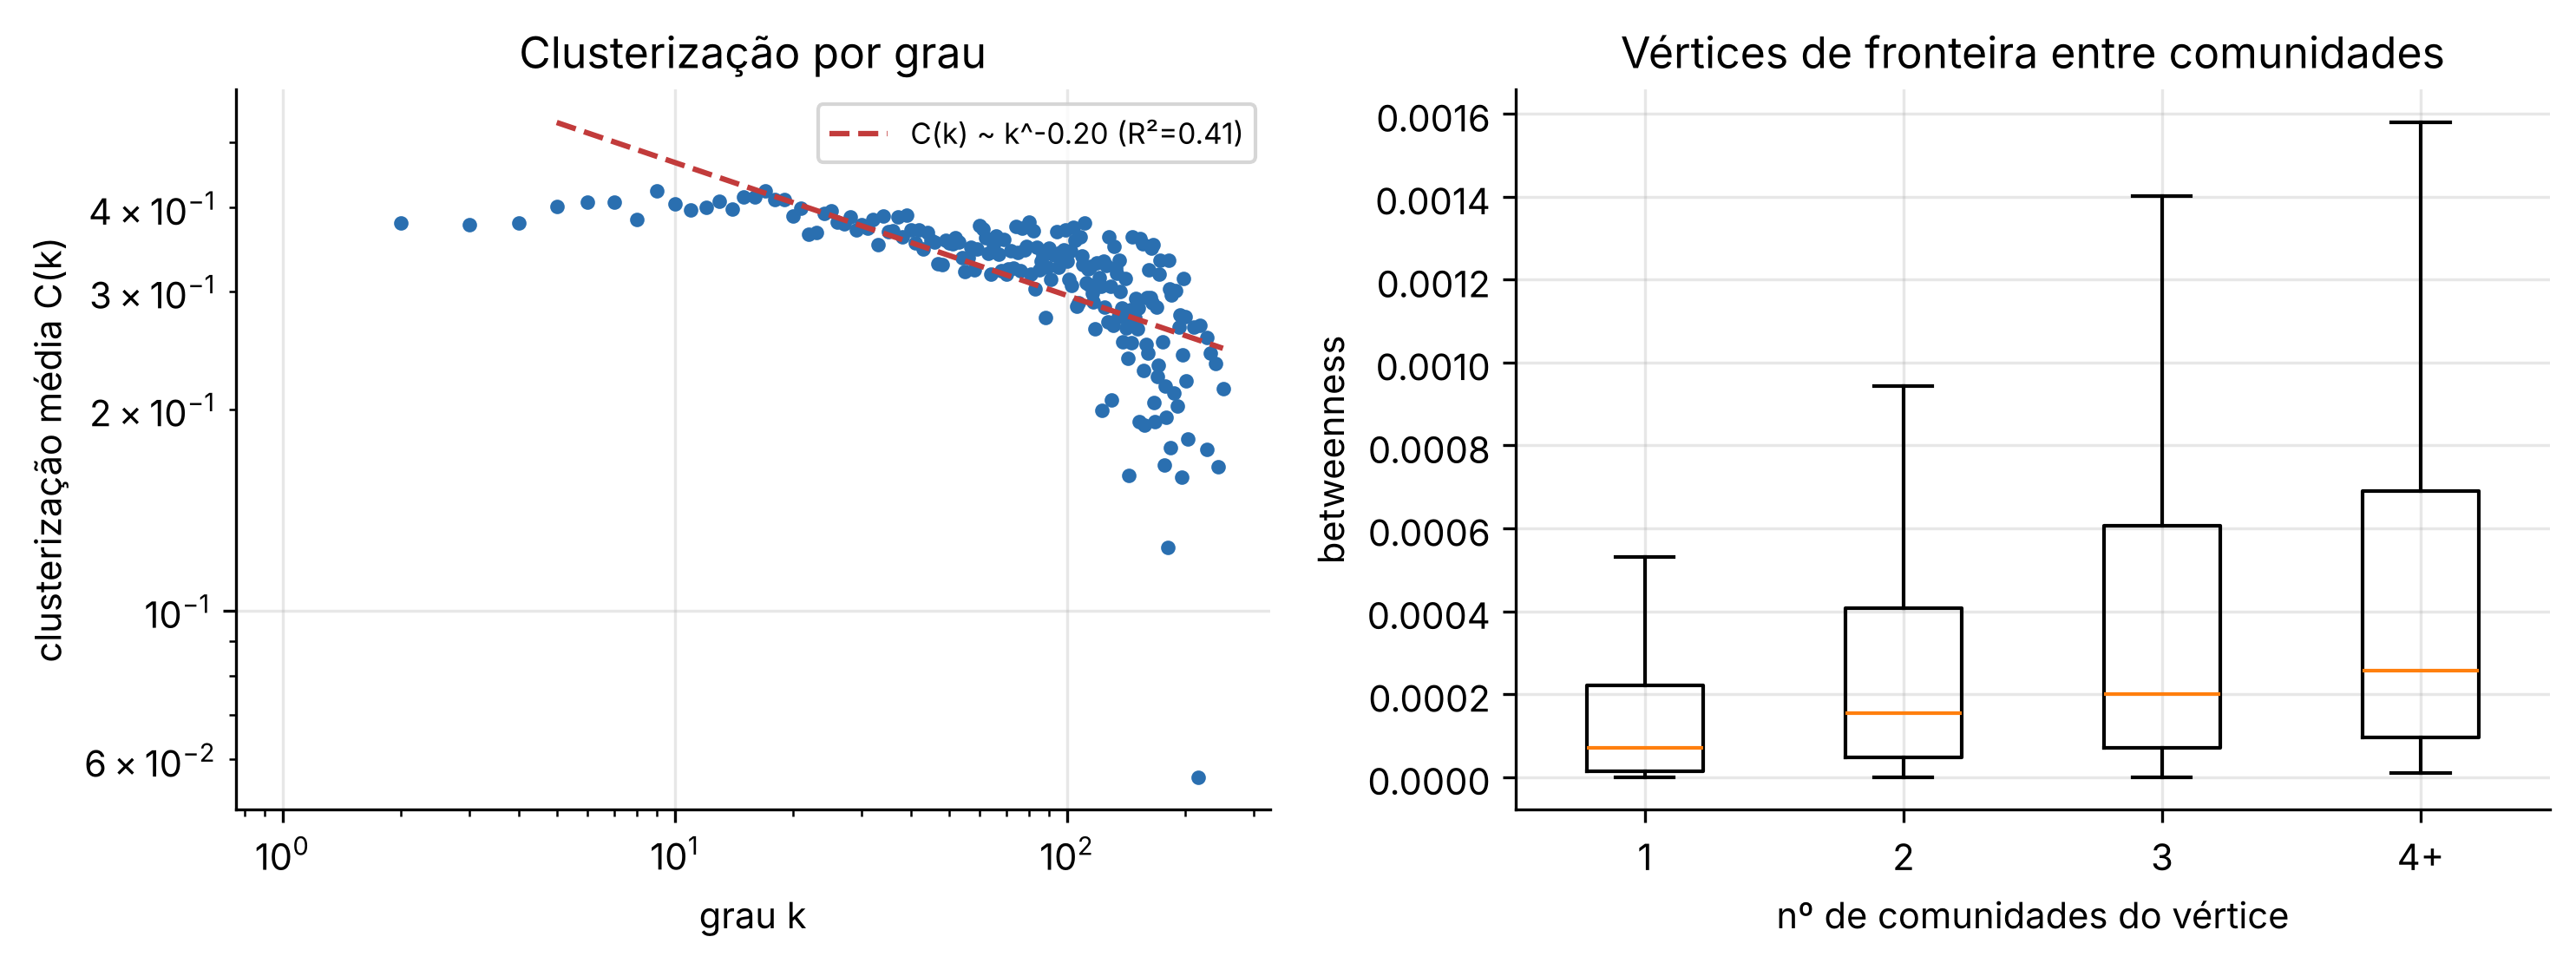

In [13]:
r6 = analise.descoberta(ctx); tabela("parte3_hubs")
print({k: v for k, v in r6.items() if k != "hubs"}); figura("p3_descoberta")

### 5. Extra — modelos clássicos (ER, BA, WS) com geradores próprios

,Modelo,n,m,grau médio,grau máx.,C,L,γ MLE,k_min,cauda (Vuong)
0,Orkut G27,9917,173413,34.972875,250,0.370304,3.764057,5.997377,119.0,exponencial
1,Erdős–Rényi,9917,173413,34.972875,59,0.003528,2.896206,19.767433,47.0,exponencial
2,Barabási–Albert (m=17),9917,168436,33.969144,568,0.017100,2.807142,2.929635,21.0,potência
3,"Watts–Strogatz (k=34, p=0,1)",9917,168589,34.000000,41,0.530687,3.596815,19.999995,34.0,exponencial


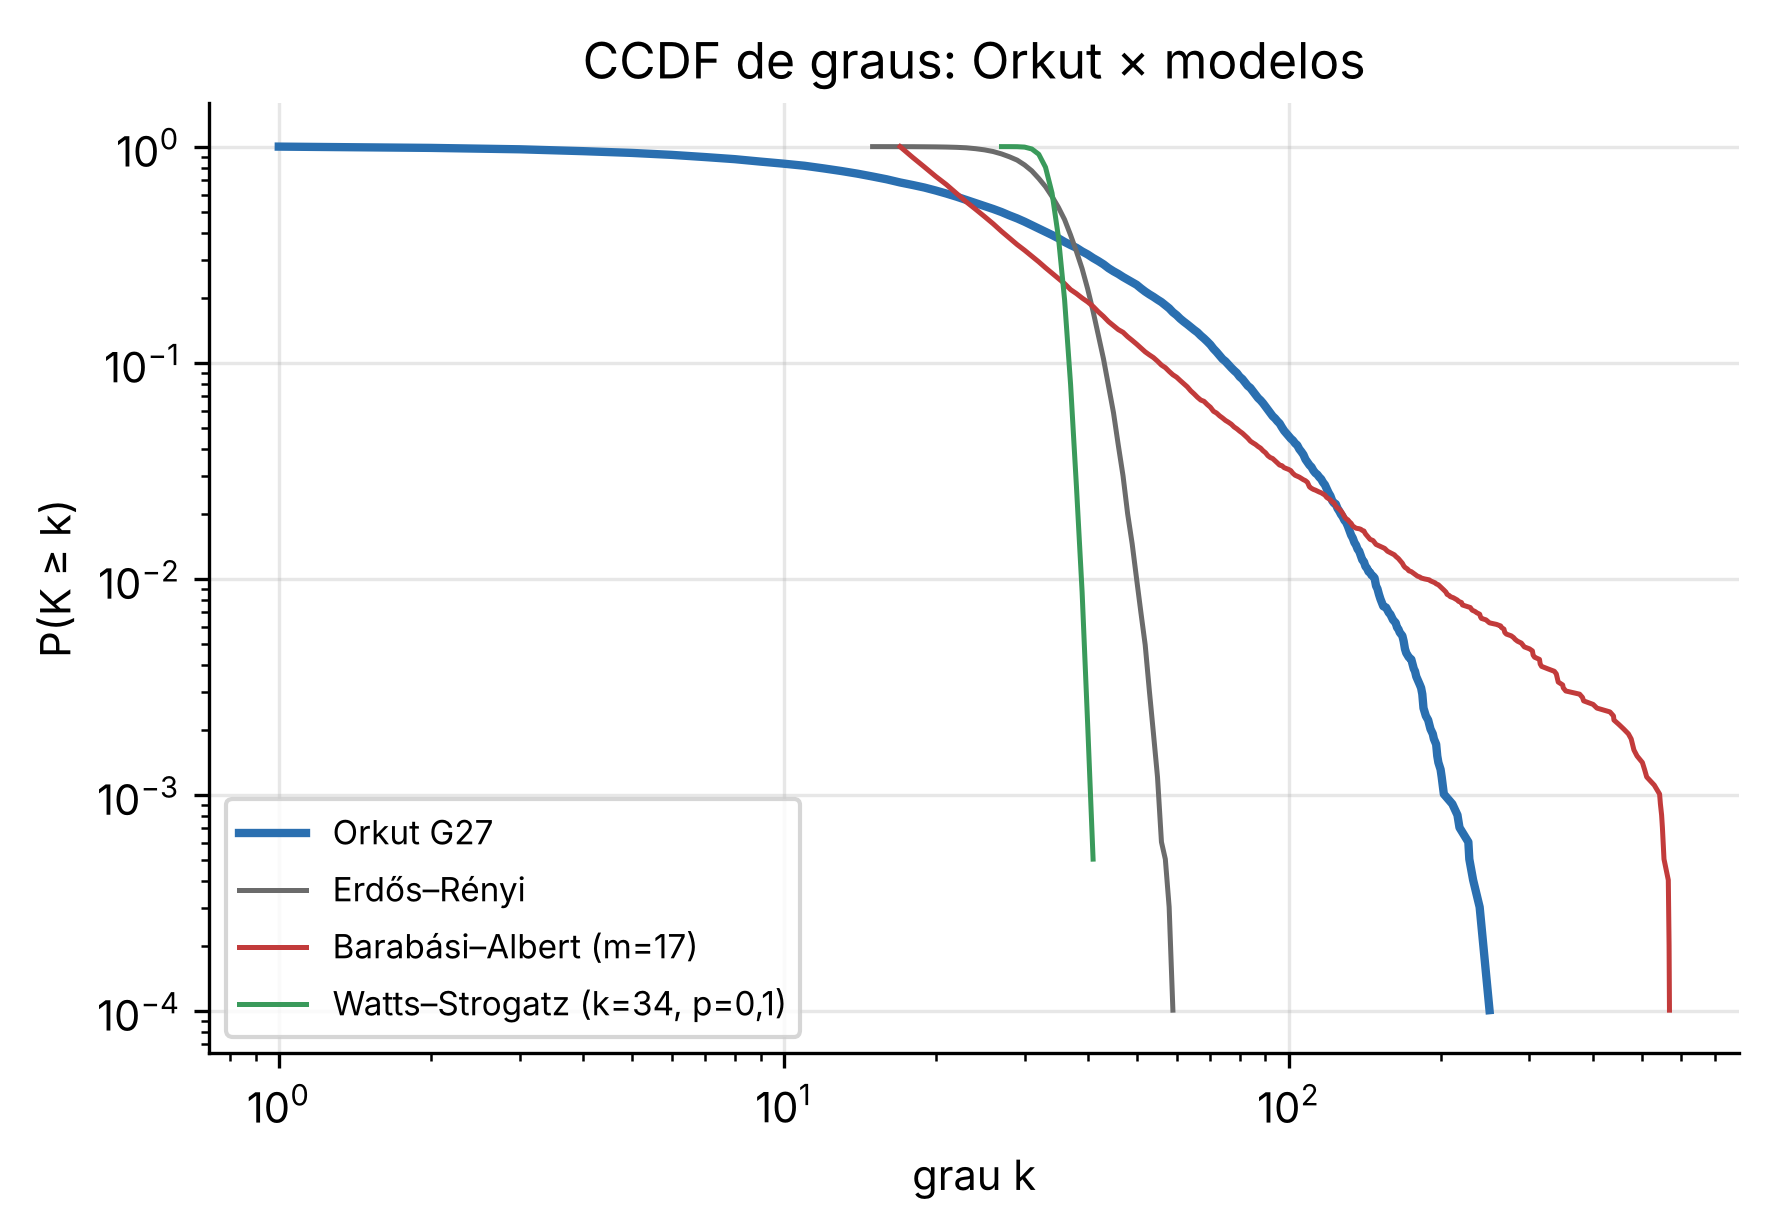

In [14]:
r7 = analise.modelos_classicos(ctx); tabela("parte3_modelos"); figura("p3_modelos_ccdf", 550)

## Consolidação (resultados.json, resultados.md, valores.tex)

In [15]:
analise.consolidar()
display(Markdown((RAIZ / "resultados" / "resultados.md").read_text(encoding="utf-8")))

# Resultados consolidados — G27 com-Orkut

Máquina: Intel(R) Xeon(R) Processor @ 2.10GHz (2 núcleos lógicos), Python 3.13.18, Linux-6.18.44-fc-v726-x86_64-with-glibc2.39.

## Parte I — estrutura

- |V| = 9,917, |E| = 173,413; grau mín./máx./médio/mediano = 1/250/34.97/26; densidade = 0.00353
- 1 componente(s); diâmetro = 9, raio = 5, caminho médio = 3.764 (exato, 98,336,972 pares ordenados)
- triângulos = 1,158,975; clusterização média = 0.3703; transitividade = 0.3276

## Parte II — algoritmos

- Euler: 4,930 vértices de grau ímpar → não euleriano nem semi-euleriano
- Tarjan: 138 pontes e 136 pontos de articulação (confere com networkx: True)
- Dijkstra com peso unitário = BFS: True; Bellman-Ford = Dijkstra: True (8 rodadas de 9,916 possíveis)
- AGM: Prim = Kruskal = 1183.4867 (igraph confere: True)
- Floyd-Warshall: validado (numpy = Python = Dijkstra) em n = 150; no grafo completo exigiria 787 MB e ~0.5 h (numpy) ou ~0.32 dias (Python puro)

| Algoritmo | Complexidade | média (ms) | DP (ms) | IC95 (ms) | método |
|---|---|---|---|---|---|
| BFS | O(n+m) | 13.140 | 0.391 | [13.001; 13.280] | Normal (z) |
| DFS | O(n+m) | 15.236 | 3.997 | [13.806; 16.666] | Normal (z) |
| Euler (verificação) | O(n+m) | 14.430 | 0.492 | [14.254; 14.607] | Normal (z) |
| Dijkstra | O((n+m) log n) | 62.806 | 9.205 | [59.512; 66.100] | Normal (z) |
| Bellman-Ford | O(n·m) [efetivo O(k·m)] | 153.392 | 10.309 | [149.702; 157.081] | Normal (z) |
| Tarjan (pontes/articulações) | O(n+m) | 31.839 | 2.245 | [31.035; 32.642] | Normal (z) |
| Prim | O(m log n) | 263.183 | 16.791 | [257.174; 269.191] | Normal (z) |
| Kruskal | O(m log m) | 109.479 | 6.055 | [107.312; 111.646] | Normal (z) |

## Parte III — redes complexas

- Small-world vs ER: C/C_rand = 105.1, L/L_rand = 1.300, σ = 80.9, ω = 0.261 → small-world: True
- Small-world vs configuração (graus preservados): C/C_conf = 34.39, L/L_conf = 1.283, σ = 26.81
- Lei de potência (MLE): subgrafo γ = 6.00 (k ≥ 119, cauda 259), vs exponencial: exponencial (p = 0.00358); Orkut completo γ = 2.96 (k ≥ 168, cauda 289,226), vs exponencial: lei de potência (p = 6.08e-252)
- Robustez (r = 496): S aleatória = 0.9992 [0.9991; 0.9993]; ataque Grau: S = 0.9990, c = 8, L = 4.025; ataque Betweenness: S = 0.9960, c = 36, L = 4.246; ataque PageRank: S = 0.9976, c = 22, L = 4.147
- Descoberta: 87.4% das arestas ficam dentro de alguma comunidade comum; C(k) ~ k^-0.20; Spearman(nº comunidades, betweenness) = 0.236

### Modelos clássicos

| Modelo | m | grau máx. | C | L | γ MLE | cauda (Vuong) |
|---|---|---|---|---|---|---|
| Orkut G27 | 173,413 | 250 | 0.3703 | 3.764 | 6.00 | exponencial |
| Erdős–Rényi | 173,413 | 59 | 0.0035 | 2.896 | 19.77 | exponencial |
| Barabási–Albert (m=17) | 168,436 | 568 | 0.0171 | 2.807 | 2.93 | potência |
| Watts–Strogatz (k=34, p=0,1) | 168,589 | 41 | 0.5307 | 3.597 | 20.00 | exponencial |

## Descoberta principal

**Os hubs não são os pontos críticos desta região do Orkut: eles ficam no núcleo redundante onde as comunidades se sobrepõem, e quem segura a periferia são outros vértices.** (i) A clusterização é 34× a de um aleatório com a MESMA sequência de graus e 87.4% das arestas ligam membros de uma mesma comunidade: o agrupamento vem das comunidades. (ii) 73% dos 496 vértices de maior grau pertencem a 2+ comunidades (média geral: 26%), ou seja, os hubs estão na zona de sobreposição, que tem muitos caminhos alternativos; removê-los desprende só 9 vértices da LCC (aleatória: 7.4). (iii) Só 147 dos 496 vértices de maior betweenness estão também no top de grau; removê-los desprende 38 vértices (36 componentes) e alonga L em 12% (grau: 7%). Mesmo assim a rede segue muito robusta (S ≥ 0.996). (iv) A lei de potência existe no Orkut completo (γ = 2.96, k ≥ 168) mas some no subgrafo (cauda exponencial): a amostragem por comunidades preserva C e L, mas corta a cauda de graus.
